<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 06: A single replicate of the $2^k$ design

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 6
(Sections 6.5 and 6.6). Problem numbers follow the 8th edition.

## Learning goals

* Compute all $2^k - 1$ effects of an unreplicated $2^k$ design and explain why the full model has no error term.
* Identify the active effects with the normal (Daniel) and half-normal probability plots and with Lenth's method
  (pseudo standard error, margin of error, simultaneous margin of error, Pareto plot).
* Project the design onto the active factors, fit and check the final model and interpret it with contour plots.
* Recognize the effect of an outlier on the normal plot of effects.
* Use a transformation of the response (log, Box-Cox) and detect dispersion effects from the residuals.

**Homework 06 — Deutschar and Blazek**

Completed required problems: 6.17, 6.28–6.29, 6.31–6.32 and 6.36.
The lecture examples are retained and executed. Only the first 16 polymer runs are used;
the center points belong to Exercise 07. Optional Problem 6.30 is not attempted.

All decisions below use $\alpha=0.05$. These are unreplicated factorial experiments:
the saturated model has no residual degrees of freedom. We use effect sparsity,
normal/half-normal plots and Lenth's approximate screening thresholds to select a
hierarchical model, then pool omitted effects to estimate error. This error is not
independently replicated pure error. ANOVA $p$-values are conditional on that model
and its normal, independent, constant-variance errors; selection on the same data
makes them exploratory rather than confirmatory.

## Setup

Run this cell first. Besides the standard imports it defines helper functions used below:

* `effects_2k()` - contrasts, effects, sums of squares and coded coefficients of a $2^k$ design (Exercise 5).
* `effect_plot()` - normal (or half-normal) probability plot of the effects with a reference line through the small effects.
* `lenth()` - Lenth's pseudo standard error $PSE$, margin of error $ME$ and simultaneous margin of error $SME$.
* `pareto_plot()` - bar chart of the absolute effects with the $ME$ and $SME$ lines.
* `residual_plots()` - normal Q-Q plot of the residuals, residuals versus fitted values and versus each factor, Shapiro-Wilk test.

In [1]:
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.graphics.factorplots import interaction_plot

from pathlib import Path
from IPython.display import display

# Local data make this notebook reproducible offline; Colab can use the course URL.
DATA_DIR = next((p for p in [Path("../data"), Path("data"), Path("01NAEX/data")]
                 if (p / "Problem_6_28.csv").is_file()), None)
URL = (str(DATA_DIR) + "/" if DATA_DIR is not None else
       "https://raw.githubusercontent.com/francji1/01NAEX/main/data/")


def effects_2k(data, response, factors):
    """Contrasts, effects, sums of squares and coded coefficients of a balanced 2^k design.

    `factors` are columns coded -1/+1 (main effects in this order: A, B, C, ...). Rows are in standard order
    (A, B, AB, C, AC, BC, ABC, ...) and are named as in statsmodels formulas ("A:B").
    """
    k = len(factors)
    n = len(data) // 2**k
    rows = []
    for i in range(1, 2**k):
        members = [factors[j] for j in range(k) if i >> j & 1]
        sign = data[members].prod(axis=1)
        contrast = (sign * data[response]).sum()
        rows.append({"term": ":".join(members), "contrast": contrast,
                     "effect": contrast / (n * 2**(k - 1)), "SS": contrast**2 / (n * 2**k)})
    table = pd.DataFrame(rows).set_index("term")
    table["coef"] = table["effect"] / 2
    return table


def effect_plot(effects, half=False, n_label=5, ax=None, title=None):
    """Normal (Daniel) or half-normal probability plot of the effects (a pd.Series indexed by the effect names).

    The reference line is fitted to the smaller half of the effects (through the origin for the half-normal plot).
    The n_label largest effects (in absolute value) are labelled.
    """
    e = (effects.abs() if half else effects).sort_values()
    m = len(e)
    p = (np.arange(1, m + 1) - 0.5) / m
    q = stats.halfnorm.ppf(p) if half else stats.norm.ppf(p)
    x = e.to_numpy(dtype=float)
    small = np.argsort(np.abs(x))[: m // 2 + 1]
    if half:
        b, a = (x[small] @ q[small]) / (q[small] @ q[small]), 0.0
        qq = np.linspace(0, q.max(), 50)
    else:
        b, a = np.polyfit(q[small], x[small], 1)
        qq = np.linspace(q.min(), q.max(), 50)
    if ax is None:
        ax = plt.subplots(figsize=(5, 4))[1]
    ax.scatter(x, q, color="k", s=20)
    ax.plot(a + b * qq, qq, color="tab:red", lw=1)
    largest = effects.abs().sort_values().index[-n_label:] if n_label else []
    for name, xi, qi in zip(e.index, x, q):
        if name in largest:
            ax.annotate(name, (xi, qi), xytext=(4, -3), textcoords="offset points")
    ax.set_xlabel("|effect|" if half else "effect")
    ax.set_ylabel("half-normal quantile" if half else "normal quantile")
    ax.set_title(title or ("Half-normal plot of effects" if half else "Normal probability plot of effects"))
    return ax


def lenth(effects, alpha=0.05):
    """Lenth's method: s0, pseudo standard error, margin of error and simultaneous margin of error."""
    c = np.abs(np.asarray(effects, dtype=float))
    m = len(c)
    s0 = 1.5 * np.median(c)
    pse = 1.5 * np.median(c[c < 2.5 * s0])
    d = m / 3
    me = stats.t.ppf(1 - alpha / 2, d) * pse
    gamma = (1 + (1 - alpha) ** (1 / m)) / 2
    sme = stats.t.ppf(gamma, d) * pse
    return {"s0": s0, "PSE": pse, "ME": me, "SME": sme}


def pareto_plot(effects, alpha=0.05, ax=None):
    """Bars of |effect| sorted by size with Lenth's ME and SME lines."""
    L = lenth(effects, alpha)
    e = effects.abs().sort_values(ascending=False)
    if ax is None:
        ax = plt.subplots(figsize=(9, 3.5))[1]
    ax.bar(e.index, e.to_numpy(), color=np.where(e > L["ME"], "tab:blue", "lightgray"))
    ax.axhline(L["ME"], color="tab:orange", ls="--", label=f"ME = {L['ME']:.2f}")
    ax.axhline(L["SME"], color="tab:red", ls="--", label=f"SME = {L['SME']:.2f}")
    ax.set_ylabel("|effect|")
    ax.tick_params(axis="x", rotation=90)
    ax.legend()
    ax.set_title("Pareto plot of the effects (Lenth)")
    return ax


def residual_plots(model, data, factors):
    """Q-Q plot, residuals vs fitted values and vs each factor; Shapiro-Wilk test of the residuals."""
    res, fit = model.resid, model.fittedvalues
    fig, axes = plt.subplots(1, 2 + len(factors), figsize=(3.3 * (2 + len(factors)), 3.2))
    sm.qqplot(res, line="s", ax=axes[0])
    axes[0].set_title("Normal Q-Q plot")
    axes[1].scatter(fit, res)
    axes[1].axhline(0, color="red", ls="--")
    axes[1].set(xlabel="fitted", ylabel="residual", title="Residuals vs fitted")
    for ax, f in zip(axes[2:], factors):
        ax.scatter(data[f], res)
        ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=f, title=f"Residuals vs {f}")
    plt.tight_layout()
    plt.show()
    print("Shapiro-Wilk on residuals:", stats.shapiro(res))

## 1. Lecture example: filtration rate ($2^4$ design, a single replicate)

Montgomery, Example 6.2: the filtration rate (gal/h) of a resin in a pilot plant. Four factors: $A$ temperature,
$B$ pressure, $C$ concentration of formaldehyde, $D$ stirring rate. One replicate of the $2^4$ design, the 16 runs in random
order. The aim is to **maximize** the filtration rate. The file lists the runs in standard order.

In [2]:
rate = pd.read_csv(URL + "Pilot_Plant_Filtration_Rate_Experiment.csv", sep=";")
factors = list("ABCD")
rate["label"] = ["".join(f.lower() for f in factors if r[f] == 1) or "(1)" for _, r in rate.iterrows()]
rate

,A,B,C,D,Rate,label
0,-1,-1,-1,-1,45,(1)
1,1,-1,-1,-1,71,a
2,-1,1,-1,-1,48,b
3,1,1,-1,-1,65,ab
4,-1,-1,1,-1,68,c
5,1,-1,1,-1,60,ac
6,-1,1,1,-1,80,bc
7,1,1,1,-1,65,abc
8,-1,-1,-1,1,43,d
9,1,-1,-1,1,100,ad


### Main effects and interaction plots

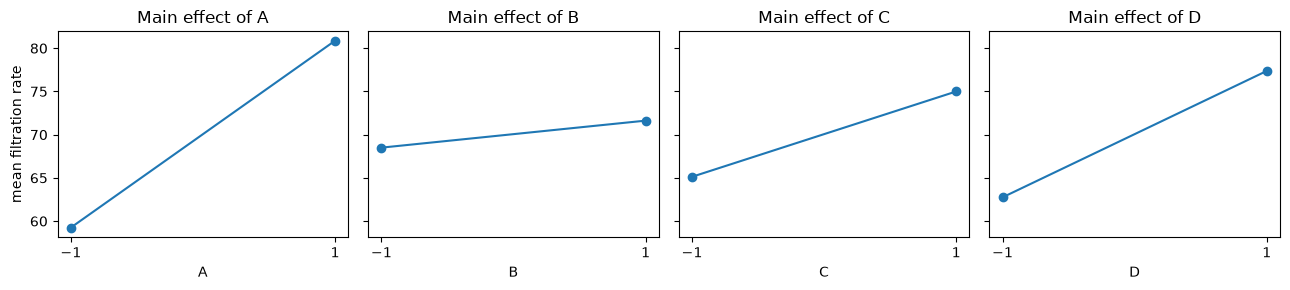

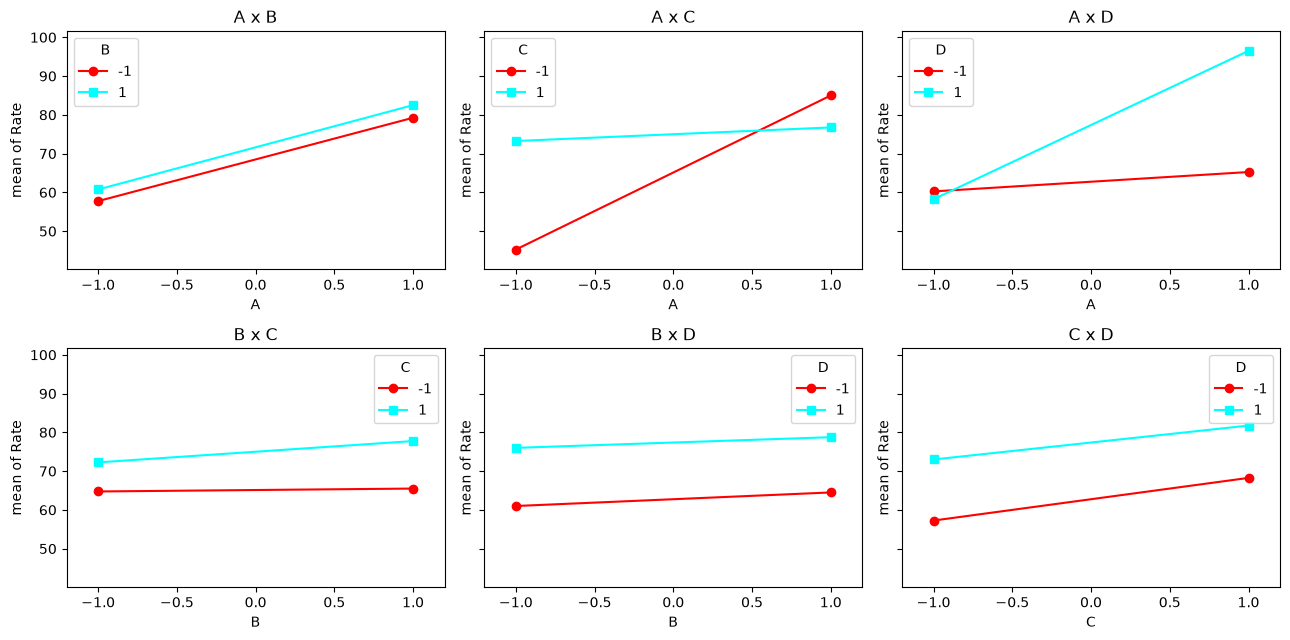

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, f in zip(axes, factors):
    m = rate.groupby(f)["Rate"].mean()
    ax.plot(m.index, m.to_numpy(), "o-")
    ax.set(xticks=[-1, 1], xlabel=f, title=f"Main effect of {f}")
axes[0].set_ylabel("mean filtration rate")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, (f1, f2) in zip(axes.flat, itertools.combinations(factors, 2)):
    interaction_plot(rate[f1], rate[f2], rate["Rate"], ax=ax, markers=["o", "s"])
    ax.set_title(f"{f1} x {f2}")
plt.tight_layout()
plt.show()

The plots suggest large main effects of $A$, $C$, $D$ and interactions $A \times C$ and $A \times D$. The lines of $B$ are
almost flat. But without an error estimate we cannot say which differences are larger than the noise.

### The full model has no error term

In [4]:
import warnings

full = smf.ols("Rate ~ A*B*C*D", data=rate).fit()
print("residual degrees of freedom:", full.df_resid)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)     # division by the zero residual df
    print(anova_lm(full).round(2))

residual degrees of freedom: 0.0
           df   sum_sq  mean_sq    F  PR(>F)
A         1.0  1870.56  1870.56  0.0     NaN
B         1.0    39.06    39.06  0.0     NaN
A:B       1.0     0.06     0.06  0.0     NaN
C         1.0   390.06   390.06  0.0     NaN
A:C       1.0  1314.06  1314.06  0.0     NaN
B:C       1.0    22.56    22.56  0.0     NaN
A:B:C     1.0    14.06    14.06  0.0     NaN
D         1.0   855.56   855.56  0.0     NaN
A:D       1.0  1105.56  1105.56  0.0     NaN
B:D       1.0     0.56     0.56  0.0     NaN
A:B:D     1.0    68.06    68.06  0.0     NaN
C:D       1.0     5.06     5.06  0.0     NaN
A:C:D     1.0    10.56    10.56  0.0     NaN
B:C:D     1.0    27.56    27.56  0.0     NaN
A:B:C:D   1.0     7.56     7.56  0.0     NaN
Residual  0.0     0.00      inf  NaN     NaN


16 observations, 16 parameters, 0 residual degrees of freedom. The sums of squares are correct, but **statsmodels prints
$F = 0$ and missing $p$-values: these are not test results.** We have to judge the effects without an estimate of $\sigma^2$.

### Effects from the table of signs

In [5]:
eff_table = effects_2k(rate, "Rate", factors)
eff = eff_table["effect"].rename(lambda t: t.replace(":", ""))      # names A, B, AB, ..., ABCD
eff_table.round(3)

,contrast,effect,SS,coef
term,,,,
A,173,21.625,1870.562,10.812
B,25,3.125,39.062,1.562
A:B,1,0.125,0.062,0.062
C,79,9.875,390.062,4.938
A:C,-145,-18.125,1314.062,-9.062
B:C,19,2.375,22.562,1.188
A:B:C,15,1.875,14.062,0.938
D,117,14.625,855.562,7.312
A:D,133,16.625,1105.562,8.312


In [6]:
# the effects are twice the regression coefficients of the full model
check = 2 * full.params.drop("Intercept")
np.allclose(check[eff_table.index], eff_table["effect"])

True

### Normal and half-normal plots of the effects

A negligible effect is $N(0, 4\sigma^2/N)$; the negligible effects lie on a straight line, the active effects are outliers.

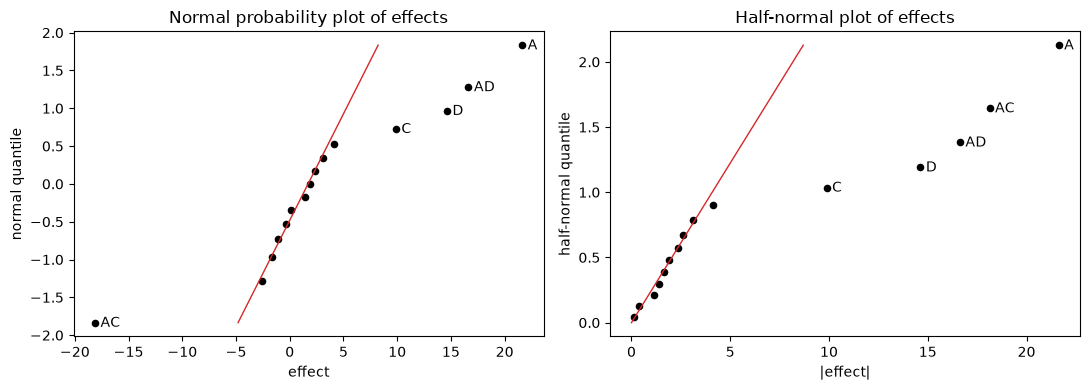

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff, ax=axes[0])
effect_plot(eff, half=True, ax=axes[1])
plt.tight_layout()
plt.show()

### Lenth's method and the Pareto plot

{'s0': np.float64(3.938), 'PSE': np.float64(2.625), 'ME': np.float64(6.748), 'SME': np.float64(13.699)}
|effect| > ME:  ['A', 'C', 'AC', 'D', 'AD']
|effect| > SME: ['A', 'AC', 'D', 'AD']


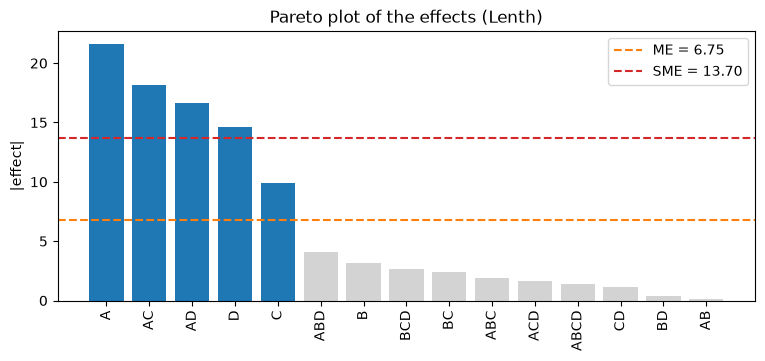

In [8]:
L = lenth(eff)
print({k: round(v, 3) for k, v in L.items()})
print("|effect| > ME: ", list(eff[eff.abs() > L["ME"]].index))
print("|effect| > SME:", list(eff[eff.abs() > L["SME"]].index))
pareto_plot(eff)
plt.show()

$PSE = 2.625$, $ME = 6.75$, $SME = 13.70$ (the same numbers as Montgomery). The effects $A$, $AC$, $AD$, $D$ exceed $SME$,
$C$ exceeds only $ME$. Because $AC$ is clearly active, we keep $C$ (hierarchy). The tentative model is
$A + C + D + AC + AD$; factor $B$ (pressure) does not appear at all.

### Projection into a replicated $2^3$ design

Dropping $B$ projects the single replicate of the $2^4$ into a $2^3$ design in $A$, $C$, $D$ with two effective replicates per corner,
provided $B$ and all its interactions are negligible. The eight error degrees of
freedom pool the contrasts involving $B$; physically these are not same-setting
replicates, so this is not independently measured pure error. (Last year's notebook built this design by stacking two copies of the $2^3$
table and pairing them with the observations in the wrong order. Fitting the model to the original data frame without $B$
avoids that mistake.)

In [9]:
m_acd = smf.ols("Rate ~ A*C*D", data=rate).fit()
anova_lm(m_acd)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,83.367688,0.000017
C,1.0,390.0625,390.0625,17.384401,0.003124
A:C,1.0,1314.0625,1314.0625,58.565460,0.000060
D,1.0,855.5625,855.5625,38.130919,0.000267
A:D,1.0,1105.5625,1105.5625,49.272981,0.000110
C:D,1.0,5.0625,5.0625,0.225627,0.647483
A:C:D,1.0,10.5625,10.5625,0.470752,0.512032
Residual,8.0,179.5000,22.4375,NaN,NaN


In [10]:
final = smf.ols("Rate ~ A + C + D + A:C + A:D", data=rate).fit()
print(anova_lm(final).round(4))
print(final.summary().tables[1])
print(f"s = {np.sqrt(final.scale):.3f}, R2 = {final.rsquared:.4f}, R2_adj = {final.rsquared_adj:.4f}")

            df     sum_sq    mean_sq        F  PR(>F)
A          1.0  1870.5625  1870.5625  95.8648  0.0000
C          1.0   390.0625   390.0625  19.9904  0.0012
D          1.0   855.5625   855.5625  43.8469  0.0001
A:C        1.0  1314.0625  1314.0625  67.3447  0.0000
A:D        1.0  1105.5625  1105.5625  56.6592  0.0000
Residual  10.0   195.1250    19.5125      NaN     NaN
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     70.0625      1.104     63.444      0.000      67.602      72.523
A             10.8125      1.104      9.791      0.000       8.352      13.273
C              4.9375      1.104      4.471      0.001       2.477       7.398
D              7.3125      1.104      6.622      0.000       4.852       9.773
A:C           -9.0625      1.104     -8.206      0.000     -11.523      -6.602
A:D            8.3125      1.104      7.527      0.000       5.852   

$$\hat y = 70.06 + 10.81\,x_1 + 4.94\,x_3 + 7.31\,x_4 - 9.06\,x_1x_3 + 8.31\,x_1x_4,$$
with $\hat\sigma = 4.42$ and $R^2 = 0.966$. The residual mean square 19.51 (10 df) pools the projected error (eight contrasts involving $B$) plus the dropped
$CD$ and $ACD$ (2 df), assuming these ten effects negligible. Check the residuals, also against the dropped factor $B$:

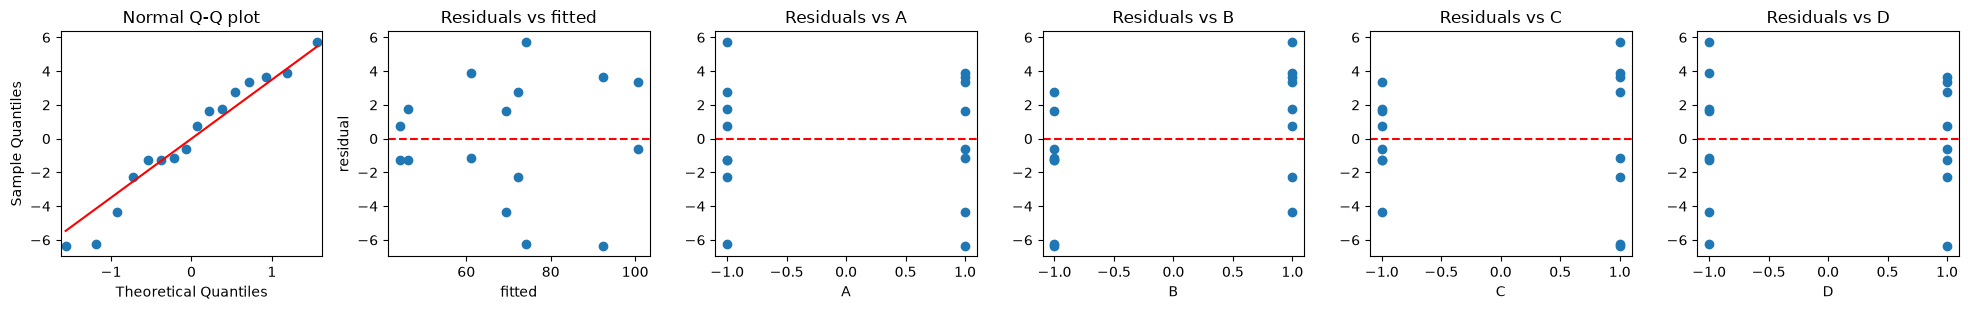

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9534713002974423), pvalue=np.float64(0.5465944420547604))


In [11]:
residual_plots(final, rate, factors)

### Contour plots and the best settings

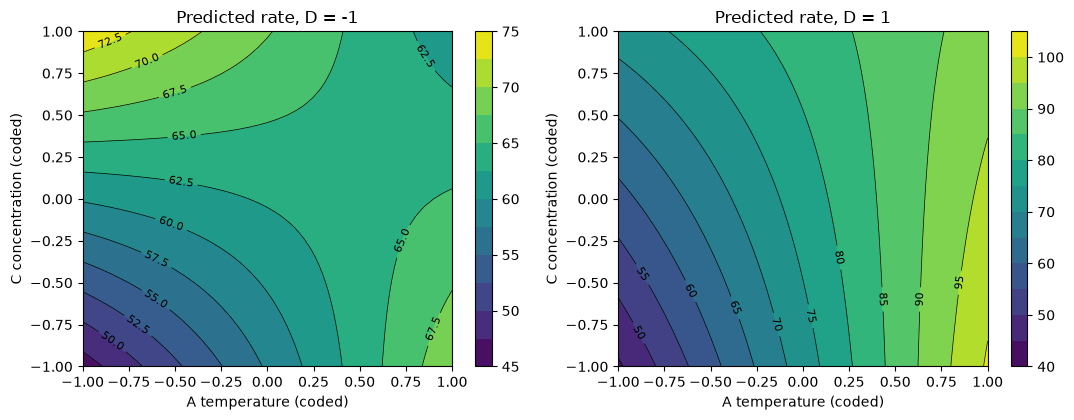

,A,C,D,predicted
5,1,-1,1,100.625
7,1,1,1,92.375
2,-1,1,-1,74.250


In [12]:
g = np.linspace(-1, 1, 41)
A, C = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, d in zip(axes, [-1, 1]):
    grid = pd.DataFrame({"A": A.ravel(), "C": C.ravel(), "D": d})
    Z = final.predict(grid).to_numpy().reshape(A.shape)
    cs = ax.contourf(A, C, Z, levels=12, cmap="viridis")
    ax.clabel(ax.contour(A, C, Z, levels=12, colors="k", linewidths=0.5), fontsize=8)
    fig.colorbar(cs, ax=ax)
    ax.set(xlabel="A temperature (coded)", ylabel="C concentration (coded)", title=f"Predicted rate, D = {d}")
plt.tight_layout()
plt.show()

corners = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "C", "D"])
corners["predicted"] = final.predict(corners)
corners.sort_values("predicted", ascending=False).head(3)

The highest predicted filtration rate (100.6 gal/h) is at high temperature, low concentration of formaldehyde and high
stirring rate ($A = +$, $C = -$, $D = +$); pressure ($B$) can be set at the cheaper level. The model is linear with
interactions and should not be extrapolated outside the cube.

### Pooling only the highest-order interaction?

In [13]:
m_3way = smf.ols("Rate ~ (A + B + C + D)**3", data=rate).fit()
anova_lm(m_3way).round(4)

,df,sum_sq,mean_sq,F,PR(>F)
A,1.0,1870.5625,1870.5625,247.3471,0.0404
B,1.0,39.0625,39.0625,5.1653,0.2639
C,1.0,390.0625,390.0625,51.5785,0.0881
D,1.0,855.5625,855.5625,113.1322,0.0597
A:B,1.0,0.0625,0.0625,0.0083,0.9423
A:C,1.0,1314.0625,1314.0625,173.7603,0.0482
A:D,1.0,1105.5625,1105.5625,146.1901,0.0525
B:C,1.0,22.5625,22.5625,2.9835,0.3341
B:D,1.0,0.5625,0.5625,0.0744,0.8305
C:D,1.0,5.0625,5.0625,0.6694,0.5635


The error term is $ABCD$ with **one** degree of freedom, $F_{0.05,1,1} = 161.4$: even the large effects $C$, $D$ and
$AD$ are not significant. Such a test has almost no power; the normal plot / Lenth's method and the projection are better.

### The effect of an outlier

Suppose the run $cd$ was recorded as 375 instead of 75 (Montgomery, Section 6.5). The error of 300 enters every effect with
weight $\pm 300/8 = \pm 37.5$.

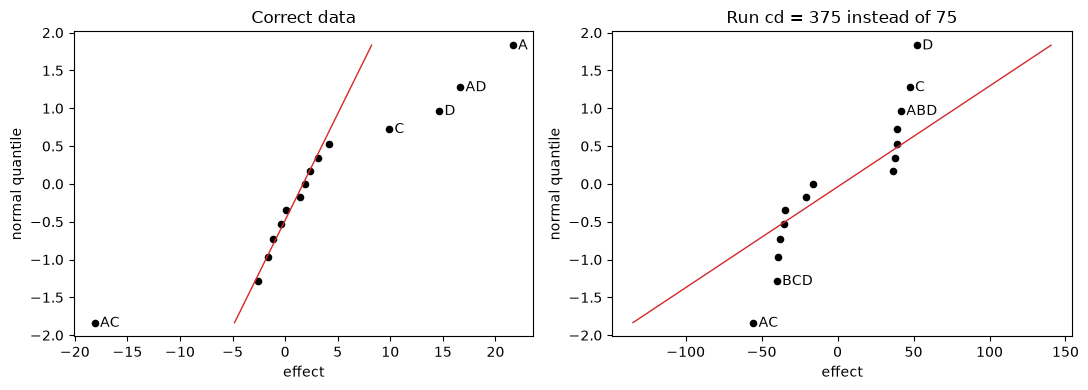

Lenth with the outlier: {'s0': np.float64(58.31), 'PSE': np.float64(58.31), 'ME': np.float64(149.9), 'SME': np.float64(304.31)}


In [14]:
bad = rate.copy()
bad.loc[bad["label"] == "cd", "Rate"] = 375
eff_bad = effects_2k(bad, "Rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
effect_plot(eff, ax=axes[0], title="Correct data")
effect_plot(eff_bad, ax=axes[1], title="Run cd = 375 instead of 75")
plt.tight_layout()
plt.show()
print("Lenth with the outlier:", {k: round(v, 2) for k, v in lenth(eff_bad).items()})

The effects split into two groups around $\pm 37.5$ with a gap in the middle; there is no straight line through the small
effects and Lenth's method finds nothing. When the normal plot looks like this, check the data first.

----

## 2. Lecture example: data transformation (drill advance rate)

Montgomery, Example 6.3 (Daniel, 1976): a single replicate of a $2^4$ design for the advance rate of a drill. Factors: drill
load ($A$), flow rate ($B$), rotational speed ($C$) and type of drilling mud ($D$). The data are read from Figure 6.19 of the
book and entered in standard order.

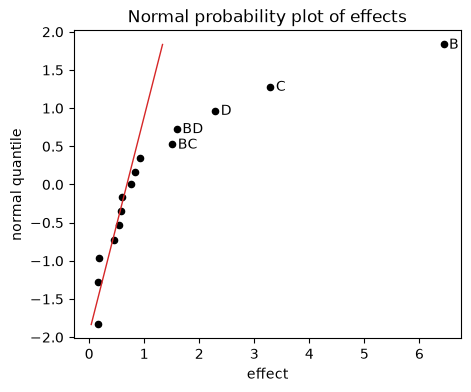

term
AC      0.155
ABC     0.163
BCD     0.175
CD      0.448
ABCD    0.543
ACD     0.585
AB      0.590
ABD     0.760
AD      0.838
A       0.918
BC      1.510
BD      1.592
D       2.290
C       3.293
B       6.438
Name: effect, dtype: float64

In [15]:
drill = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=factors)
drill["rate"] = [1.68, 1.98, 4.98, 5.70, 3.24, 3.44, 9.97, 9.07,
                 2.07, 2.44, 7.77, 9.43, 4.09, 4.53, 11.75, 16.30]
eff_drill = effects_2k(drill, "rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_drill)
plt.show()
eff_drill.sort_values().round(3)

On the original scale $B$, $C$, $D$ and the interactions $BC$, $BD$ look active. Fit this model and look at the residuals:

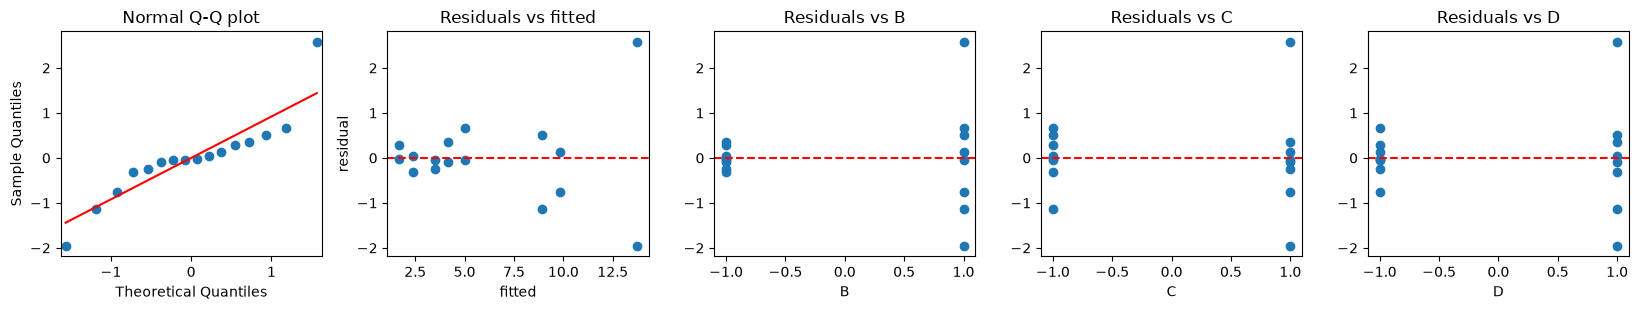

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.8811859327432726), pvalue=np.float64(0.04049249331426929))


In [16]:
m_raw = smf.ols("rate ~ B + C + D + B:C + B:D", data=drill).fit()
residual_plots(m_raw, drill, ["B", "C", "D"])

The residuals form a **funnel**: their spread grows with the predicted advance rate. The response is a rate, the effects are
likely multiplicative, so try the log transformation. A quick Box-Cox check: residual sum of squares of the model $B + C + D$
for the scaled power transformation $y^{(\lambda)} = (y^\lambda - 1)/(\lambda \dot y^{\lambda - 1})$ ($\dot y$ = geometric
mean, $\lambda = 0$: $\dot y \ln y$), so that the values are comparable across $\lambda$.

In [17]:
gm = np.exp(np.log(drill["rate"]).mean())
for lam in [1, 0.5, 0, -0.5, -1]:
    if lam == 0:
        y_lam = gm * np.log(drill["rate"])
    else:
        y_lam = (drill["rate"]**lam - 1) / (lam * gm**(lam - 1))
    ssr = smf.ols("y ~ B + C + D", data=drill.assign(y=y_lam)).fit().ssr
    print(f"lambda = {lam:5.1f}: residual SS = {ssr:6.2f}")

lambda =   1.0: residual SS =  32.81
lambda =   0.5: residual SS =  10.55
lambda =   0.0: residual SS =   4.21
lambda =  -0.5: residual SS =   7.87
lambda =  -1.0: residual SS =  23.26


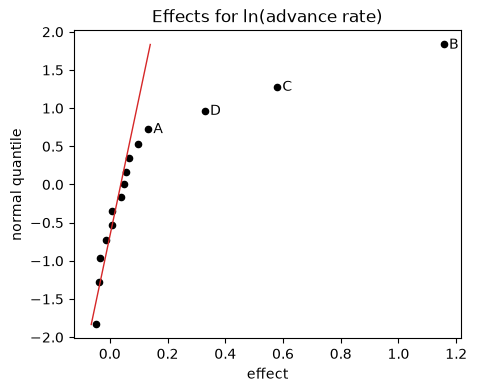

            df  sum_sq  mean_sq         F  PR(>F)
B          1.0  5.3452   5.3452  371.4928  0.0000
C          1.0  1.3389   1.3389   93.0517  0.0000
D          1.0  0.4305   0.4305   29.9224  0.0001
Residual  12.0  0.1727   0.0144       NaN     NaN
R2 = 0.9763


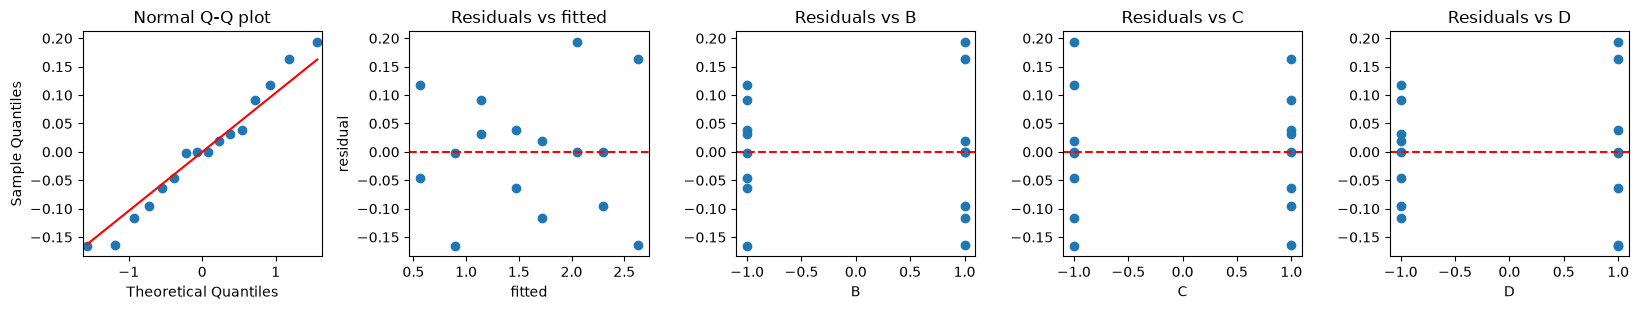

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9681448904190898), pvalue=np.float64(0.8077359536002))


In [18]:
drill["log_rate"] = np.log(drill["rate"])
eff_log = effects_2k(drill, "log_rate", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_log, n_label=4, title="Effects for ln(advance rate)")
plt.show()

m_log = smf.ols("log_rate ~ B + C + D", data=drill).fit()
print(anova_lm(m_log).round(4))
print(f"R2 = {m_log.rsquared:.4f}")
residual_plots(m_log, drill, ["B", "C", "D"])

After the log transformation only the main effects $B$, $C$, $D$ are active, the interactions disappeared and the residuals
look fine ($R^2 = 0.976$). Predictions are computed on the log scale and transformed back with `np.exp` (this estimates
the median of the advance rate):

In [19]:
new = pd.DataFrame({"B": [1], "C": [1], "D": [1]})
print("predicted advance rate at B = C = D = +1:", np.exp(m_log.predict(new)).round(2).iloc[0])

predicted advance rate at B = C = D = +1: 13.85


----

## 3. Lecture example: location and dispersion effects (panel process)

Montgomery, Example 6.4: a single replicate of a $2^4$ design in a process producing interior panels for aircraft. Response:
the average number of defects per panel in a press load. Factors: temperature $A$ (295, 325 $^\circ$F), clamp time $B$
(7, 9 min), resin flow $C$ (10, 20), closing time $D$ (15, 30 s). Data from Figure 6.26 of the book, in standard order.

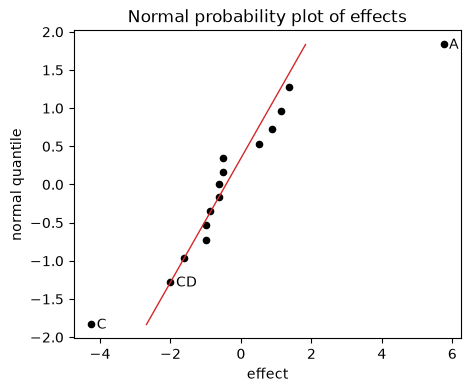

Intercept    6.688
A            2.875
C           -2.125
dtype: float64 R2 = 0.775


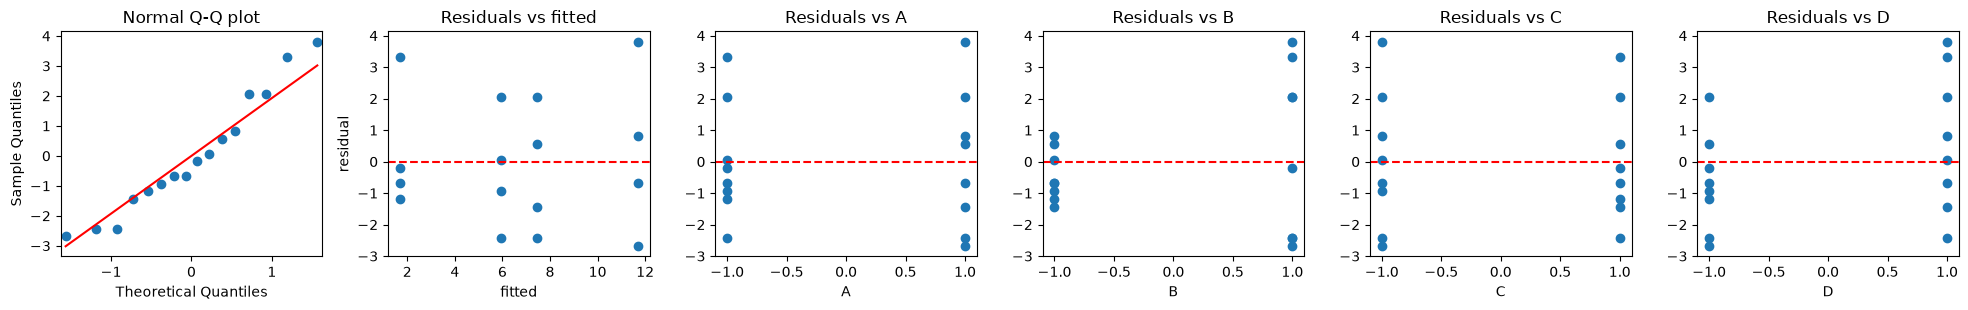

Shapiro-Wilk on residuals: ShapiroResult(statistic=np.float64(0.9427968216833551), pvalue=np.float64(0.3846952959373613))


In [20]:
panel = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=factors)
panel["defects"] = [5, 11, 3.5, 9, 0.5, 8, 1.5, 9.5, 6, 12.5, 8, 15.5, 1, 6, 5, 5]
eff_panel = effects_2k(panel, "defects", factors)["effect"].rename(lambda t: t.replace(":", ""))
effect_plot(eff_panel, n_label=3)
plt.show()

m_loc = smf.ols("defects ~ A + C", data=panel).fit()
print(m_loc.params.round(3), f"R2 = {m_loc.rsquared:.3f}")
residual_plots(m_loc, panel, factors)

Location effects: $A = 5.75$ and $C = -4.25$, so low temperature and high resin flow reduce the number of defects. The plot
of the residuals against $B$ (clamp time) shows a much larger spread at the high level of $B$. For every column of the table
of signs we compute the **dispersion effect**
$$F_i^* = \ln \frac{S^2(i^+)}{S^2(i^-)},$$
where $S(i^\pm)$ is the standard deviation of the residuals at the runs where the column is $\pm$.

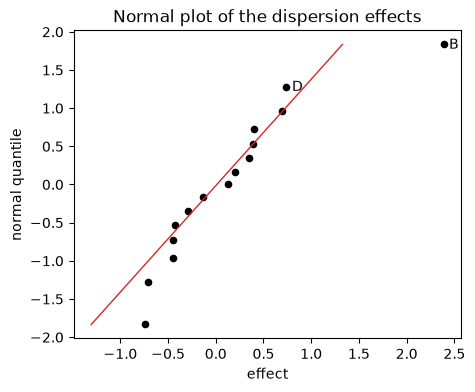

ABCD   -0.74
ACD    -0.71
BC     -0.45
ABC    -0.44
AC     -0.43
C      -0.29
ABD    -0.14
AD      0.13
BCD     0.20
AB      0.35
A       0.39
CD      0.40
BD      0.69
D       0.74
B       2.39
dtype: float64

In [21]:
e = m_loc.resid
Fstar = {}
for t in eff_panel.index:
    s = panel[list(t)].prod(axis=1)
    Fstar[t] = np.log(e[s == 1].var() / e[s == -1].var())
Fstar = pd.Series(Fstar)
effect_plot(Fstar, n_label=2, title="Normal plot of the dispersion effects")
plt.show()
Fstar.sort_values().round(2)

$F_B^* = 2.39$ stands out: clamp time does not change the mean number of defects, but the low clamp time gives a smaller
variability. Recommended: low temperature and high resin flow (location), low clamp time (dispersion).

----

## Assignment

Work on the assignment in class (in pairs, if you like). Whatever you do not finish in class, finish at home as homework.

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition): **6.17, 6.28 with 6.29,
  6.31 with 6.32 and 6.36**; Problem 6.30 is optional.
* Use the normal (or half-normal) plot of the effects together with Lenth's method to choose the model, respect the
  hierarchy, state the hypotheses, the test statistic, its $p$-value and your decision for the final model, check the
  residuals and end each problem with a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex06_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 8 November 2026** (the next lecture is on
  9 November; Team Project 1 has the same deadline).

### Reporting conventions for the solutions

For each ANOVA term, $H_0$ sets that term's coded coefficient(s) to zero,
and $H_1$ allows at least one to be nonzero, conditional on the other retained terms.
The table reports $F=MS_{term}/MS_E$, numerator and denominator degrees of freedom,
$p=P(F_{df_1,df_E}\ge F_{obs})$, and the decision. In these orthogonal factorial models
the term sums of squares are unchanged by the order of terms. For the overall model,
$H_0$ sets all non-intercept coefficients to zero, and $H_1$ has at least one nonzero.

Lenth's $PSE$, $ME$ and $SME$ are approximate screening summaries, not an ordinary
residual $t$-test. We distinguish effects exceeding the individual $ME$ from those
exceeding the simultaneous $SME$; hierarchy can retain a parent below either line.
For Shapiro–Wilk, $H_0$ is normally distributed errors versus non-normal errors;
the reported $W$ and $p$ are diagnostic, because fitted residuals are correlated.
Failure to reject never proves normality or independence. The files list standard
factorial order, so row order cannot be used to diagnose actual time drift.

In [22]:
alpha = 0.05

def screen(data=None, response=None, factors=None, effects=None, title=""):
    """Report all contrasts and both Lenth thresholds, with effect plots."""
    if effects is None:
        table = effects_2k(data, response, factors)
        display(table.round(6))
        effects = table.effect.rename(lambda t: t.replace(":", ""))
    limits = lenth(effects, alpha)
    display(pd.Series(limits, name="Lenth thresholds").to_frame())
    print("Exceed ME:", list(effects.index[effects.abs() > limits["ME"]]))
    print("Exceed SME:", list(effects.index[effects.abs() > limits["SME"]]))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    effect_plot(effects, ax=axes[0], title=title + ": normal plot")
    effect_plot(effects, half=True, ax=axes[1], title=title + ": half-normal plot")
    pareto_plot(effects, ax=axes[2])
    plt.tight_layout()
    plt.show()
    return effects, limits

def report_model(model, title):
    print(title, "\nFormula:", model.model.formula)
    display(model.params.rename("coded coefficient").to_frame())
    a = anova_lm(model)
    a["df denominator"] = model.df_resid
    a["decision (0.05)"] = [
        "reject H0" if p < alpha else "do not reject H0" if np.isfinite(p) else "error estimate"
        for p in a["PR(>F)"]]
    display(a)
    print(f"Overall H0: all slopes = 0; F({int(model.df_model)}, {int(model.df_resid)})"
          f" = {model.fvalue:.6g}, p = {model.f_pvalue:.6g}; "
          + ("reject H0" if model.f_pvalue < alpha else "do not reject H0"))
    print(f"SSE = {model.ssr:.6g}; MSE = {model.mse_resid:.6g}; "
          f"s = {np.sqrt(model.mse_resid):.6g}; R2 = {model.rsquared:.6g}")
    return a

def diagnostics(model, data, factors, title):
    """Q-Q and residual plots, with the actual diagnostic decisions."""
    nplots = 2 + len(factors)
    fig, axes = plt.subplots(2, 3, figsize=(13, 7))
    axes = axes.ravel()
    sm.qqplot(model.resid, line="s", ax=axes[0])
    axes[0].set_title("Normal Q-Q")
    axes[1].scatter(model.fittedvalues, model.resid)
    axes[1].axhline(0, color="red", ls="--")
    axes[1].set(xlabel="Fitted response", ylabel="Residual")
    for ax, f in zip(axes[2:], factors):
        ax.scatter(data[f], model.resid)
        ax.axhline(0, color="red", ls="--")
        ax.set(xlabel=f + " (coded)", ylabel="Residual", xticks=[-1, 1])
    for ax in axes[nplots:]:
        ax.set_visible(False)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    W, p = stats.shapiro(model.resid)
    print(f"Shapiro-Wilk H0: normal errors. W = {W:.6g}, p = {p:.6g}: "
          + ("reject H0" if p < alpha else "do not reject H0"))
    return W, p

### Problem 6.17

An experimenter has run a single replicate of a $2^4$ design. The following effect estimates have been calculated:

| Effect | Estimate | Effect | Estimate | Effect | Estimate |
|---|---|---|---|---|---|
| $A$ | 76.95 | $AB$ | $-51.32$ | $ABC$ | $-2.82$ |
| $B$ | $-67.52$ | $AC$ | 11.69 | $ABD$ | $-6.50$ |
| $C$ | $-7.84$ | $AD$ | 9.78 | $ACD$ | 10.20 |
| $D$ | $-18.73$ | $BC$ | 20.78 | $BCD$ | $-7.98$ |
| | | $BD$ | 14.74 | $ABCD$ | $-6.25$ |
| | | $CD$ | 1.27 | | |

(a) Construct a normal probability plot of these effects.

(b) Identify a tentative model, based on the plot of the effects in part (a).

(c) (Added.) Apply Lenth's method. Does it lead to the same model?

**Solution (a)–(c).** The normal plot suggests $A$, $B$ and $AB$ depart from the
small-effect line. The hierarchical tentative model is
$$\hat y=\hat\beta_0+38.475A-33.760B-25.660AB,$$
where $\hat\beta_0$ is the unknown grand mean. The estimates supplied determine
slopes (one half of each effect) but do not supply the response mean.

,effect
A,76.95
B,-67.52
C,-7.84
D,-18.73
AB,-51.32
AC,11.69
AD,9.78
BC,20.78
BD,14.74
CD,1.27


,Lenth thresholds
s0,15.300000
PSE,13.320000
ME,34.240150
SME,69.512435


Exceed ME: ['A', 'B', 'AB']
Exceed SME: ['A']


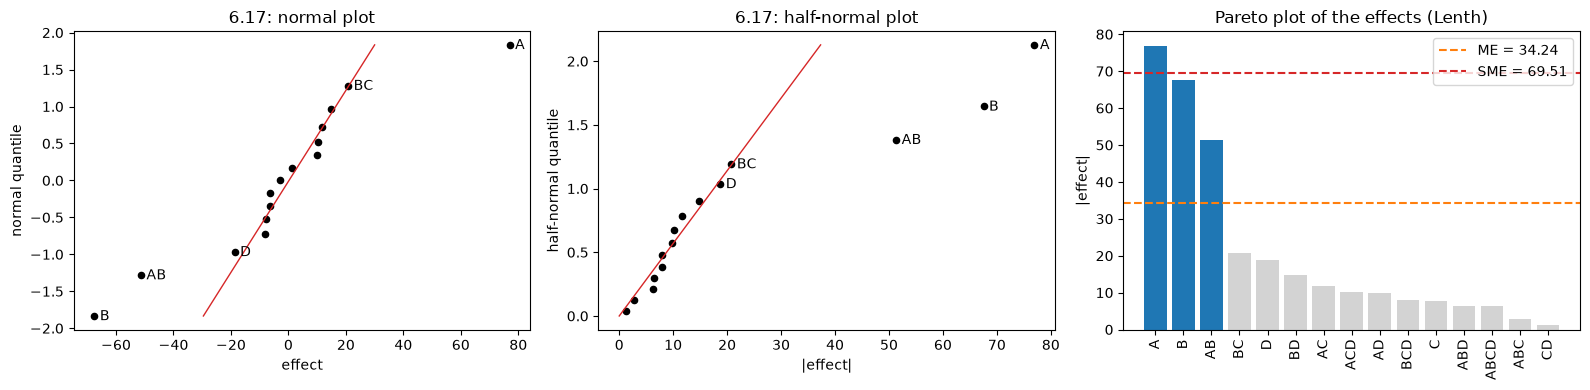

In [23]:
e617 = pd.Series({
    "A": 76.95, "B": -67.52, "C": -7.84, "D": -18.73,
    "AB": -51.32, "AC": 11.69, "AD": 9.78, "BC": 20.78,
    "BD": 14.74, "CD": 1.27, "ABC": -2.82, "ABD": -6.50,
    "ACD": 10.20, "BCD": -7.98, "ABCD": -6.25,
}, name="effect")
display(e617.to_frame())
_, limits617 = screen(effects=e617, title="6.17")

$PSE=13.32$, $ME=34.2402$, $SME=69.5124$. The individual screen selects
$A,B,AB$, agreeing with the plot; only $A$ exceeds the simultaneous threshold.
Thus this is a tentative three-effect model, not evidence that all three pass a
familywise 5% screen. $AB<0$ means increasing $A$ is much more helpful when $B$ is low:
the simple $A$ effects are $76.95-(-51.32)=128.27$ at $B=-1$ and
$76.95+(-51.32)=25.63$ at $B=+1$.

Although the grand mean is unknown, **all fifteen** non-intercept effects are
available. Orthogonality therefore determines every centered response:
$$y_i-\bar y=\tfrac12\sum_{t\ne I} effect_t\,s_{it},$$
where $s_{it}$ is the sign of effect $t$ at run $i$. Reconstruct the centered
responses, fit $A*B$ and pool the other twelve contrasts. This permits conditional
ANOVA and residual diagnostics; the omitted grand mean affects only the intercept.
The reconstructed data inherit the rounding of the supplied effects.

6.17: conditional pooled ANOVA from centered responses 
Formula: centered_y ~ A*B


,coded coefficient
Intercept,0.000
A,38.475
B,-33.760
A:B,-25.660


,df,sum_sq,mean_sq,F,PR(>F),df denominator,decision (0.05)
A,1.0,23685.2100,23685.210000,45.775681,0.000020,12.0,reject H0
B,1.0,18235.8016,18235.801600,35.243776,0.000069,12.0,reject H0
A:B,1.0,10534.9696,10534.969600,20.360613,0.000711,12.0,reject H0
Residual,12.0,6209.0288,517.419067,NaN,NaN,12.0,error estimate


Overall H0: all slopes = 0; F(3, 12) = 33.7934, p = 3.93061e-06; reject H0
SSE = 6209.03; MSE = 517.419; s = 22.7468; R2 = 0.894161


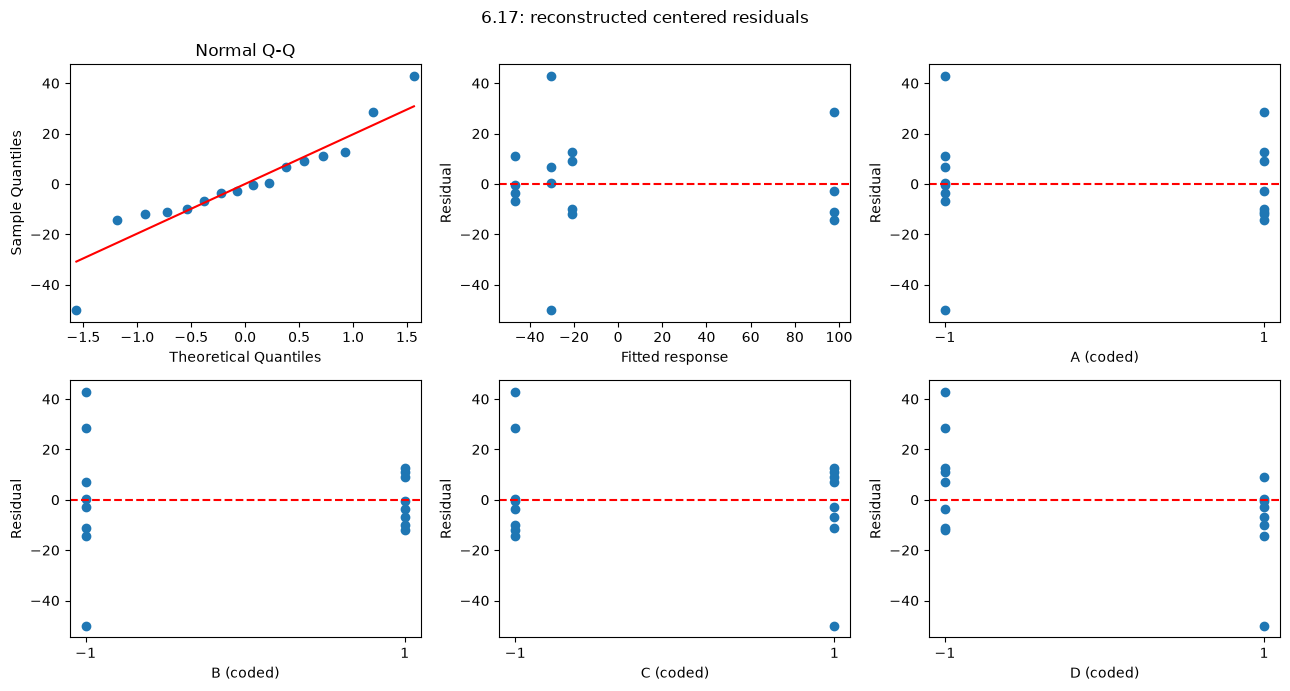

Shapiro-Wilk H0: normal errors. W = 0.931046, p = 0.253263: do not reject H0


(np.float64(0.9310460742258703), np.float64(0.25326339343525855))

In [24]:
centered617 = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)],
                           columns=list("ABCD"))
centered617["centered_y"] = sum(
    0.5*effect*centered617[list(term)].prod(axis=1)
    for term, effect in e617.items())
m617 = smf.ols("centered_y ~ A*B", data=centered617).fit()
a617 = report_model(m617, "6.17: conditional pooled ANOVA from centered responses")
assert np.isclose(centered617.centered_y.mean(), 0)
assert np.allclose(2*m617.params[["A", "B", "A:B"]], e617[["A", "B", "AB"]])
diagnostics(m617, centered617, list("ABCD"), "6.17: reconstructed centered residuals")

The pooled error has $SS_E=6209.0288$, $MS_E=517.4191$ on 12 df.
The displayed conditional tests reject the zero-coefficient nulls for $A$, $B$ and
$AB$ ($F=45.7757$, $35.2438$ and $20.3606$, respectively). This does not turn
Lenth's individual screen into a simultaneous result: the ANOVA depends on
assuming the other twelve effects negligible and uses the same data for selection.
The residual normality diagnostic does not reject ($W=0.9310$, $p=0.2533$);
there is no pronounced funnel in the plotted residuals. Rounded effects and only
sixteen observations limit diagnosis, and standard order is not actual run order.

**Conclusion.** Investigate $A$, $B$ and their interaction first, with both parents
retained. The supplied effects support a pooled-error exploratory model and its
residual diagnostics; absolute response predictions still require the grand mean,
and independent replication would provide a stronger error estimate.

### Problems 6.28 and 6.29: process development (yield)

In a process development study on yield, four factors were studied, each at two levels: time ($A$: 2.5 and 3 h),
concentration ($B$: 14 and 18 %), pressure ($C$: 60 and 80 psi) and temperature ($D$: 225 and 250 $^\circ$C). A single
replicate of a $2^4$ design was run. The file `Problem_6_28.csv` contains the factor levels in natural units and the
yield (lbs) in standard order (the actual run order is given in Table P6.7 of the book).

In [25]:
p628 = pd.read_csv(URL + "Problem_6_28.csv")
p628

,Time,Concentration,Pressure,Temperature,Yield
0,2.5,14,60,225,12
1,3.0,14,60,225,18
2,2.5,18,60,225,13
3,3.0,18,60,225,16
4,2.5,14,80,225,17
5,3.0,14,80,225,15
6,2.5,18,80,225,20
7,3.0,18,80,225,15
8,2.5,14,60,250,10
9,3.0,14,60,250,25


**Problem 6.28**

(a) Construct a normal probability plot of the effect estimates. Which factors appear to have large effects?

(b) Conduct an analysis of variance using the normal probability plot in part (a) for guidance in forming an error term.
What are your conclusions?

(c) Write down a regression model relating yield to the important process variables.

(d) Analyze the residuals from this experiment. Does your analysis indicate any potential problems?

(e) Can this design be collapsed into a $2^3$ design with two replicates? If so, sketch the design with the average and range
of yield shown at each point in the cube. Interpret the results.

Hint: first code the factors to $-1$/$+1$, for example `np.where(p628["Time"] == 3, 1, -1)`.

**Solution 6.28 (a)–(c).** Code $A=(Time-2.75)/0.25$,
$B=(Concentration-16)/2$, $C=(Pressure-70)/10$ and
$D=(Temperature-237.5)/12.5$. The largest effects are $A=4.5$, $AC=-4.25$,
$AD=4.0$ and $D=3.25$. Keep $C=2.0$ as a parent of $AC$ even though it is below
$ME=2.8919$. None exceeds $SME=5.8710$, so the combined plot/sparsity/hierarchy
argument, followed by the conditional ANOVA, is more informative than a claim of
simultaneous Lenth significance.

,contrast,effect,SS,coef
term,,,,
A,36.0,4.50,81.00,2.250
B,4.0,0.50,1.00,0.250
A:B,-6.0,-0.75,2.25,-0.375
C,16.0,2.00,16.00,1.000
A:C,-34.0,-4.25,72.25,-2.125
B:C,2.0,0.25,0.25,0.125
A:B:C,8.0,1.00,4.00,0.500
D,26.0,3.25,42.25,1.625
A:D,32.0,4.00,64.00,2.000


,Lenth thresholds
s0,1.125000
PSE,1.125000
ME,2.891905
SME,5.870983


Exceed ME: ['A', 'AC', 'D', 'AD']
Exceed SME: []


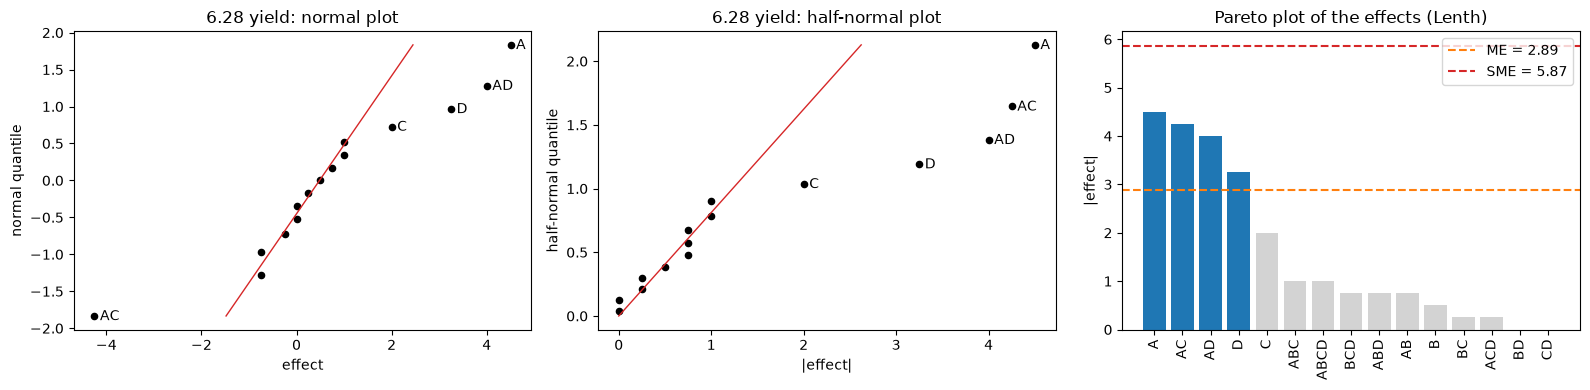

6.28: hierarchical yield model 
Formula: Yield ~ A*C + A*D


,coded coefficient
Intercept,17.375
A,2.250
C,1.000
A:C,-2.125
D,1.625
A:D,2.000


,df,sum_sq,mean_sq,F,PR(>F),df denominator,decision (0.05)
A,1.0,81.00,81.000,49.846154,0.000035,10.0,reject H0
C,1.0,16.00,16.000,9.846154,0.010549,10.0,reject H0
A:C,1.0,72.25,72.250,44.461538,0.000056,10.0,reject H0
D,1.0,42.25,42.250,26.000000,0.000465,10.0,reject H0
A:D,1.0,64.00,64.000,39.384615,0.000092,10.0,reject H0
Residual,10.0,16.25,1.625,NaN,NaN,10.0,error estimate


Overall H0: all slopes = 0; F(5, 10) = 33.9077, p = 5.85569e-06; reject H0
SSE = 16.25; MSE = 1.625; s = 1.27475; R2 = 0.944302


In [26]:
for f, col, mid, half in zip(
    "ABCD", ["Time", "Concentration", "Pressure", "Temperature"],
    [2.75, 16, 70, 237.5], [0.25, 2, 10, 12.5]):
    p628[f] = (p628[col] - mid) / half
e628, limits628 = screen(p628, "Yield", list("ABCD"), title="6.28 yield")
m628 = smf.ols("Yield ~ A*C + A*D", data=p628).fit()
a628 = report_model(m628, "6.28: hierarchical yield model")

The fitted coded model is
$$\hat y=17.375+2.250A+1.000C+1.625D-2.125AC+2.000AD.$$
Pooling the ten omitted effects gives $SS_E=16.25$ and $MS_E=1.625$ (10 df).
The tests of $A,C,D,AC,AD$ all reject their zero-coefficient nulls; the table gives
the exact statistics and $p$-values (the largest is $p_C=0.01055$).
Factor $B$ is absent: changing concentration has little evidence of a mean effect
within this region. The significant interactions make recommendations conditional
on settings, rather than a simple list of positive main effects.

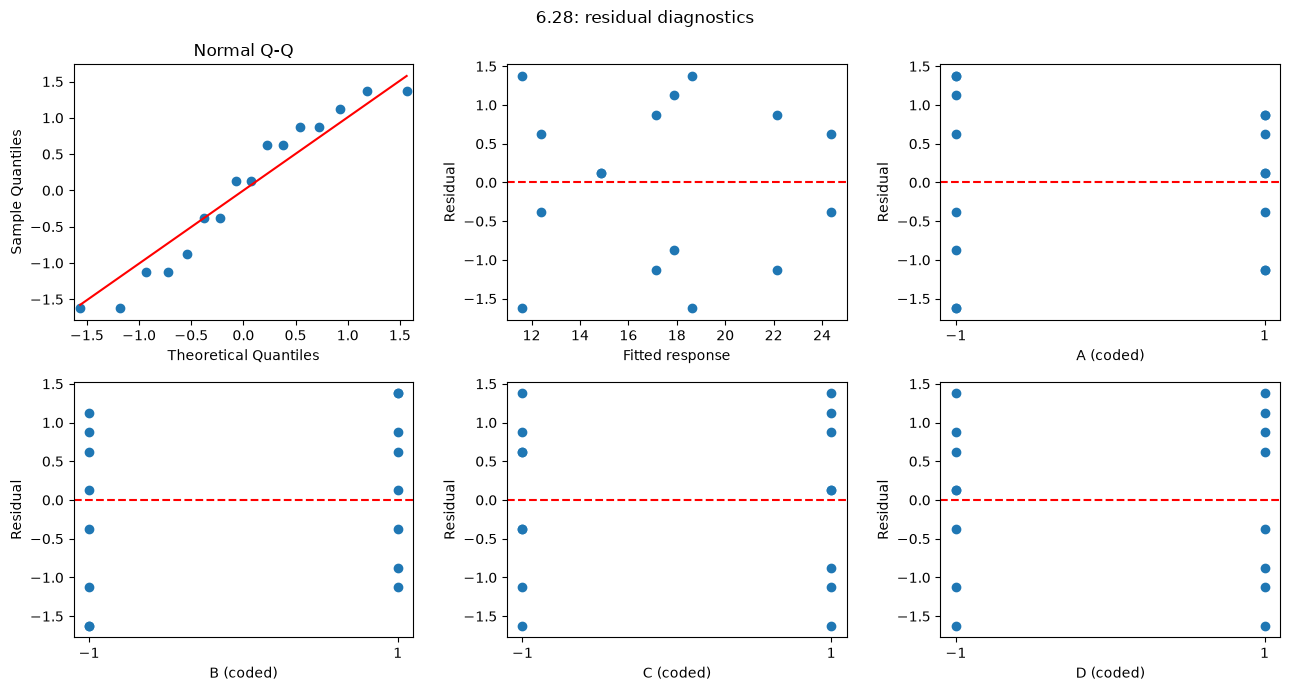

Shapiro-Wilk H0: normal errors. W = 0.922696, p = 0.186388: do not reject H0


,A,C,D,mean,minimum,maximum,n,range
0,-1.0,-1.0,-1.0,12.5,12,13,2,1
1,-1.0,-1.0,1.0,11.5,10,13,2,3
2,-1.0,1.0,-1.0,18.5,17,20,2,3
3,-1.0,1.0,1.0,18.0,17,19,2,2
4,1.0,-1.0,-1.0,17.0,16,18,2,2
5,1.0,-1.0,1.0,24.5,24,25,2,1
6,1.0,1.0,-1.0,15.0,15,15,2,0
7,1.0,1.0,1.0,22.0,21,23,2,2


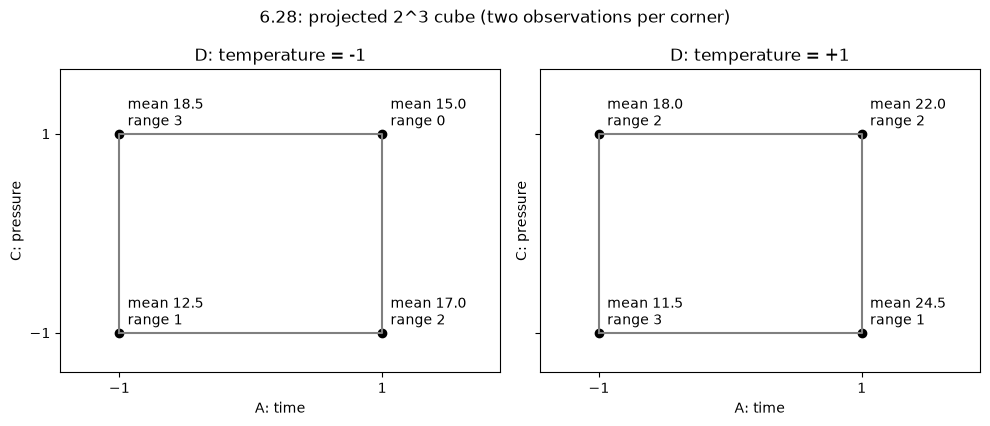

In [27]:
diagnostics(m628, p628, list("ABCD"), "6.28: residual diagnostics")
project628 = (p628.groupby(["A", "C", "D"])["Yield"]
              .agg(mean="mean", minimum="min", maximum="max", n="size")
              .reset_index())
project628["range"] = project628.maximum - project628.minimum
display(project628)

# Two schematic slices of the cube: each label gives the projected mean and range.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), sharey=True)
for ax, d in zip(axes, [-1, 1]):
    sub = project628[project628.D == d]
    ax.plot([-1, 1, 1, -1, -1], [-1, -1, 1, 1, -1], color="grey")
    for _, r in sub.iterrows():
        ax.scatter(r.A, r.C, color="black")
        ax.annotate(f"mean {r['mean']:.1f}\nrange {r['range']:.0f}",
                    (r.A, r.C), xytext=(6, 6), textcoords="offset points")
    ax.set(xlim=(-1.45, 1.9), ylim=(-1.4, 1.65), xticks=[-1, 1], yticks=[-1, 1],
           xlabel="A: time", ylabel="C: pressure", title=f"D: temperature = {d:+d}")
fig.suptitle("6.28: projected 2^3 cube (two observations per corner)")
plt.tight_layout()
plt.show()

**(d)** Shapiro–Wilk gives $W=0.9227$, $p=0.1864$, so it does not reject normality.
The residuals lie between $-1.625$ and $1.375$; the plots do not show a pronounced
funnel or curvature pattern. The spread is somewhat larger at low $A$, but the
sample is too small to establish a stable variance difference. No obvious
outlier calls for deletion, and independence depends on the original randomization.

**(e)** Dropping $B$ projects the design into a $2^3$ in $A,C,D$ with two
observations per corner. These are only *effective* replicates under the assumption
that $B$ and its interactions are negligible; physically they were run at different
concentrations. The table and cube preserve the original row pairing. Their highest
mean is 24.5 lbs, range 1, at $A=+1,C=-1,D=+1$.

**Conclusion.** Use a longer time (3 h), lower pressure (60 psi) and higher
temperature (250 °C) to maximize yield in the studied region; concentration may
be selected for cost, followed by independent confirmation runs.

**Problem 6.29.** Use the regression model in part (c) of Problem 6.28 to generate a response surface contour plot of yield.
Discuss the practical value of this response surface plot.

**Solution 6.29.** Plot time against pressure in natural units, with a panel for
each temperature. A separate panel is necessary because the time–temperature
interaction changes the slope. Concentration is not in the selected model.

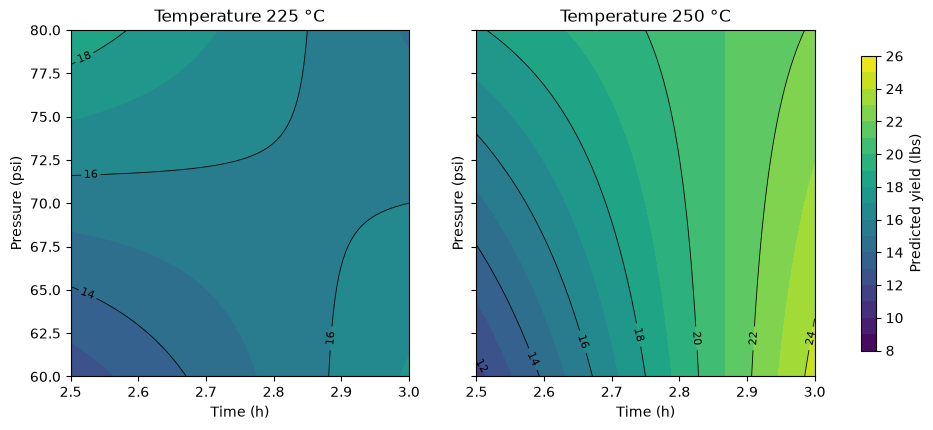

,A,C,D,prediction
5,1,-1,1,24.375
7,1,1,1,22.125
2,-1,1,-1,18.625
3,-1,1,1,17.875
4,1,-1,-1,17.125
6,1,1,-1,14.875
0,-1,-1,-1,12.375
1,-1,-1,1,11.625


In [28]:
g = np.linspace(-1, 1, 101)
aa, cc = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, d, temp in zip(axes, [-1, 1], [225, 250]):
    grid = pd.DataFrame({"A": aa.ravel(), "C": cc.ravel(), "D": d})
    zz = m628.predict(grid).to_numpy().reshape(aa.shape)
    cs = ax.contourf(2.75 + 0.25*aa, 70 + 10*cc, zz, levels=np.linspace(8, 26, 19))
    lines = ax.contour(2.75 + 0.25*aa, 70 + 10*cc, zz, levels=np.arange(10, 27, 2),
                       colors="k", linewidths=0.6)
    ax.clabel(lines, fontsize=8)
    ax.set(xlabel="Time (h)", ylabel="Pressure (psi)", title=f"Temperature {temp} °C")
fig.colorbar(cs, ax=axes, label="Predicted yield (lbs)", shrink=0.85)
plt.show()
corners628 = pd.DataFrame(list(itertools.product([-1, 1], repeat=3)), columns=["A", "C", "D"])
corners628["prediction"] = m628.predict(corners628)
display(corners628.sort_values("prediction", ascending=False))

The pressure slope is $1-2.125A$: increasing pressure helps at short time but
hurts at long time. The temperature slope is $1.625+2A$: higher temperature
mainly helps at long time. The time slope is $2.25-2.125C+2D$, so the advantage
of longer time is strongest at low pressure and high temperature.

**Conclusion.** The contour plot makes the interactions and promising operating
region visible. The predicted best corner is 24.375 lbs at 3 h, 60 psi and 250 °C;
it is a local recommendation inside the tested rectangle, not evidence for an
unbounded improvement or an estimate of quadratic curvature.

### Problems 6.31 and 6.32: a polymer (molecular weight and viscosity)

An experiment was conducted on a chemical process that produces a polymer. The four factors studied were temperature
($A$: 100 and 120 $^\circ$C), catalyst concentration ($B$: 4 and 8 %), time ($C$: 20 and 30 min) and pressure ($D$: 60 and
75 psi). Two responses, molecular weight and viscosity, were observed. The file `Problem_6_31.txt` contains the 16 runs of the
$2^4$ design in standard order followed by 4 center points.

**Use only the first 16 runs** (the factorial part). The center points and the test for curvature (part (b) of 6.31)
will come in Lecture 7.

In [29]:
p631 = pd.read_csv(URL + "Problem_6_31.txt", sep=";")
p631 = p631.iloc[:16].copy()          # the 2^4 runs only
p631

,Temperature,Concentration,Time,Pressure,Weight,Viscosity
0,100,4,20,60.0,2400,1400
1,120,4,20,60.0,2410,1500
2,100,8,20,60.0,2315,1520
3,120,8,20,60.0,2510,1630
4,100,4,30,60.0,2615,1380
5,120,4,30,60.0,2625,1525
6,100,8,30,60.0,2400,1500
7,120,8,30,60.0,2750,1620
8,100,4,20,75.0,2400,1400
9,120,4,20,75.0,2390,1525


**Problem 6.31**

(a) Consider only the molecular weight response. Plot the effect estimates on a normal probability scale. What effects
appear important?

(b) Use an analysis of variance to confirm the results from part (a).

(c) Write down a regression model to predict molecular weight as a function of the important variables.

(d) Analyze the residuals and comment on model adequacy.

(e) Repeat parts (a)-(d) using the viscosity response.

**Solution 6.31 (a)–(e).** Use only the 16 factorial runs. The coding is
$A=(Temperature-110)/10$, $B=(Concentration-6)/2$,
$C=(Time-25)/5$, $D=(Pressure-67.5)/7.5$.

For molecular weight, $C=201.25$, $A=123.75$, $AB=120$ exceed $SME=112.5272$.
Keep the small $B=-11.25$ main effect to respect hierarchy.
For viscosity, $A=96.25$ and $B=91.25$ exceed $ME=53.0183$ but not
$SME=107.6347$; the plot separates them from the small effects. Fit $A+B$.

,contrast,effect,SS,coef
term,,,,
A,990.0,123.75,61256.25,61.875
B,-90.0,-11.25,506.25,-5.625
A:B,960.0,120.00,57600.00,60.000
C,1610.0,201.25,162006.25,100.625
A:C,160.0,20.00,1600.00,10.000
B:C,-180.0,-22.50,2025.00,-11.250
A:B:C,130.0,16.25,1056.25,8.125
D,50.0,6.25,156.25,3.125
A:D,-140.0,-17.50,1225.00,-8.750


,Lenth thresholds
s0,26.250000
PSE,21.562500
ME,55.428171
SME,112.527168


Exceed ME: ['A', 'AB', 'C']
Exceed SME: ['A', 'AB', 'C']


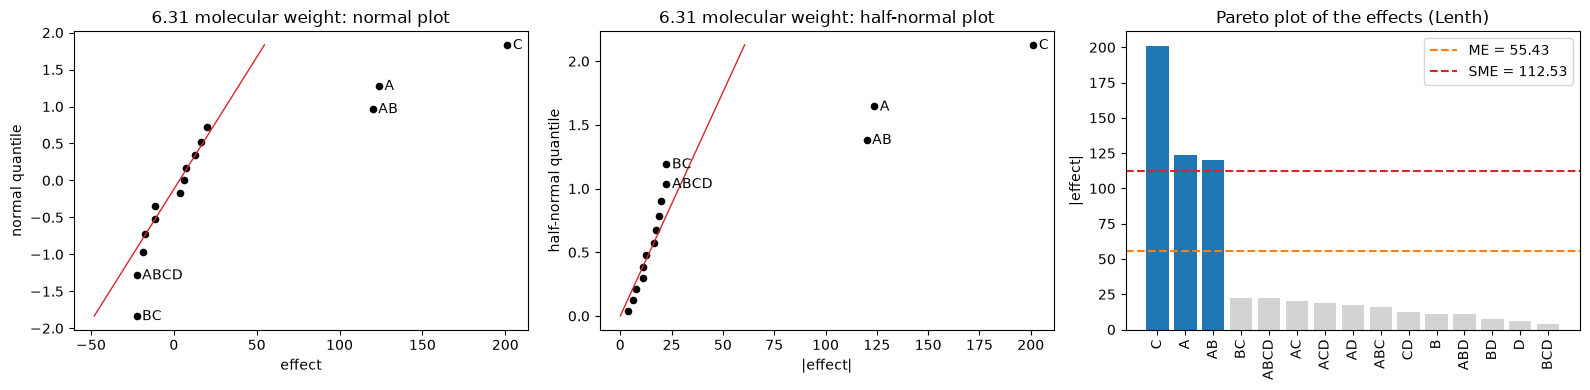

6.31: molecular weight 
Formula: Weight ~ A*B + C


,coded coefficient
Intercept,2506.250
A,61.875
B,-5.625
A:B,60.000
C,100.625


,df,sum_sq,mean_sq,F,PR(>F),df denominator,decision (0.05)
A,1.0,61256.25,61256.250000,61.782808,7.721183e-06,11.0,reject H0
B,1.0,506.25,506.250000,0.510602,4.897653e-01,11.0,do not reject H0
A:B,1.0,57600.00,57600.000000,58.095129,1.031806e-05,11.0,reject H0
C,1.0,162006.25,162006.250000,163.398854,6.060089e-08,11.0,reject H0
Residual,11.0,10906.25,991.477273,NaN,NaN,11.0,error estimate


Overall H0: all slopes = 0; F(4, 11) = 70.9468, p = 8.79712e-08; reject H0
SSE = 10906.2; MSE = 991.477; s = 31.4877; R2 = 0.962685


,contrast,effect,SS,coef
term,,,,
A,770.0,96.25,37056.25,48.125
B,730.0,91.25,33306.25,45.625
A:B,-110.0,-13.75,756.25,-6.875
C,60.0,7.50,225.00,3.750
A:C,100.0,12.50,625.00,6.250
B:C,80.0,10.00,400.00,5.000
A:B:C,120.0,15.00,900.00,7.500
D,-140.0,-17.50,1225.00,-8.750
A:D,-180.0,-22.50,2025.00,-11.250


,Lenth thresholds
s0,22.500000
PSE,20.625000
ME,53.018250
SME,107.634682


Exceed ME: ['A', 'B']
Exceed SME: []


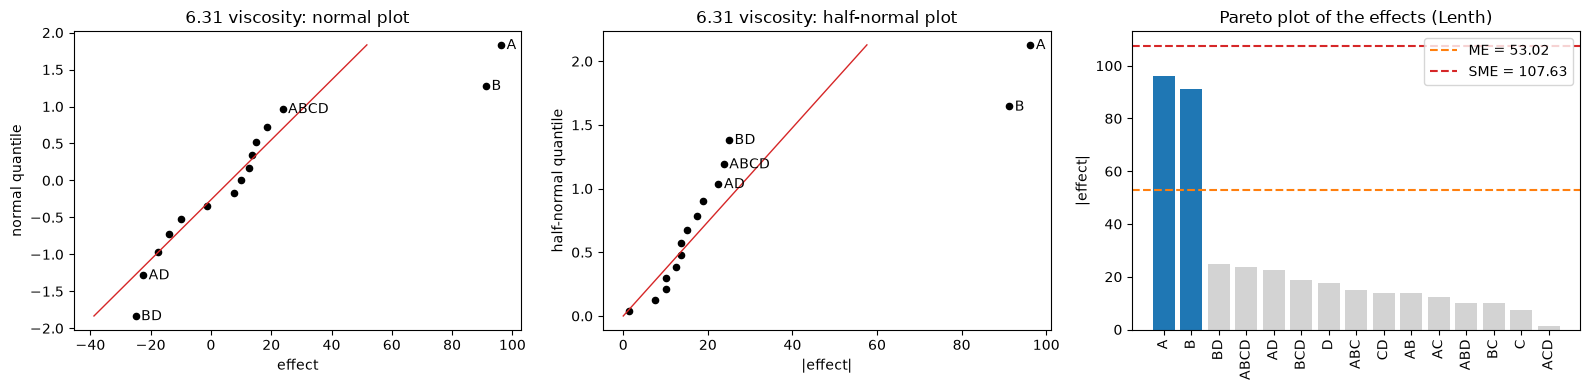

6.31: viscosity 
Formula: Viscosity ~ A + B


,coded coefficient
Intercept,1500.625
A,48.125
B,45.625


,df,sum_sq,mean_sq,F,PR(>F),df denominator,decision (0.05)
A,1.0,37056.25,37056.250000,35.733426,0.000046,13.0,reject H0
B,1.0,33306.25,33306.250000,32.117293,0.000077,13.0,reject H0
Residual,13.0,13481.25,1037.019231,NaN,NaN,13.0,error estimate


Overall H0: all slopes = 0; F(2, 13) = 33.9254, p = 6.92925e-06; reject H0
SSE = 13481.2; MSE = 1037.02; s = 32.2028; R2 = 0.83921


In [30]:
for f, col, mid, half in zip(
    "ABCD", ["Temperature", "Concentration", "Time", "Pressure"],
    [110, 6, 25, 67.5], [10, 2, 5, 7.5]):
    p631[f] = (p631[col] - mid) / half
e631w, limits631w = screen(p631, "Weight", list("ABCD"), title="6.31 molecular weight")
m631w = smf.ols("Weight ~ A*B + C", data=p631).fit()
a631w = report_model(m631w, "6.31: molecular weight")
e631v, limits631v = screen(p631, "Viscosity", list("ABCD"), title="6.31 viscosity")
m631v = smf.ols("Viscosity ~ A + B", data=p631).fit()
a631v = report_model(m631v, "6.31: viscosity")

The coded prediction equations are
$$\widehat{Weight}=2506.250+61.875A-5.625B+100.625C+60.000AB,$$
$$\widehat{Viscosity}=1500.625+48.125A+45.625B.$$

For weight, $MS_E=991.4773$ on 11 df. Reject $H_0$ for $A,C,AB$;
do not reject it for $B$ ($F=0.5106$, $p=0.4898$), but retain $B$ because of
$AB$. The simple effect of increasing temperature is only $3.75$ at low catalyst
concentration, but $243.75$ at high concentration. Raising time from 20 to 30 min
increases predicted weight by $201.25$ at all $A,B$ settings in this model.

For viscosity, $MS_E=1037.0192$ on 13 df. Reject the zero-effect nulls for both
$A$ ($F=35.7334$, $p\simeq4.61\times10^{-5}$) and $B$
($F=32.1173$, $p\simeq7.68\times10^{-5}$). Moving from low to high temperature
or concentration increases predicted viscosity by $96.25$ or $91.25$,
respectively. These results are conditional on pooling the omitted effects.

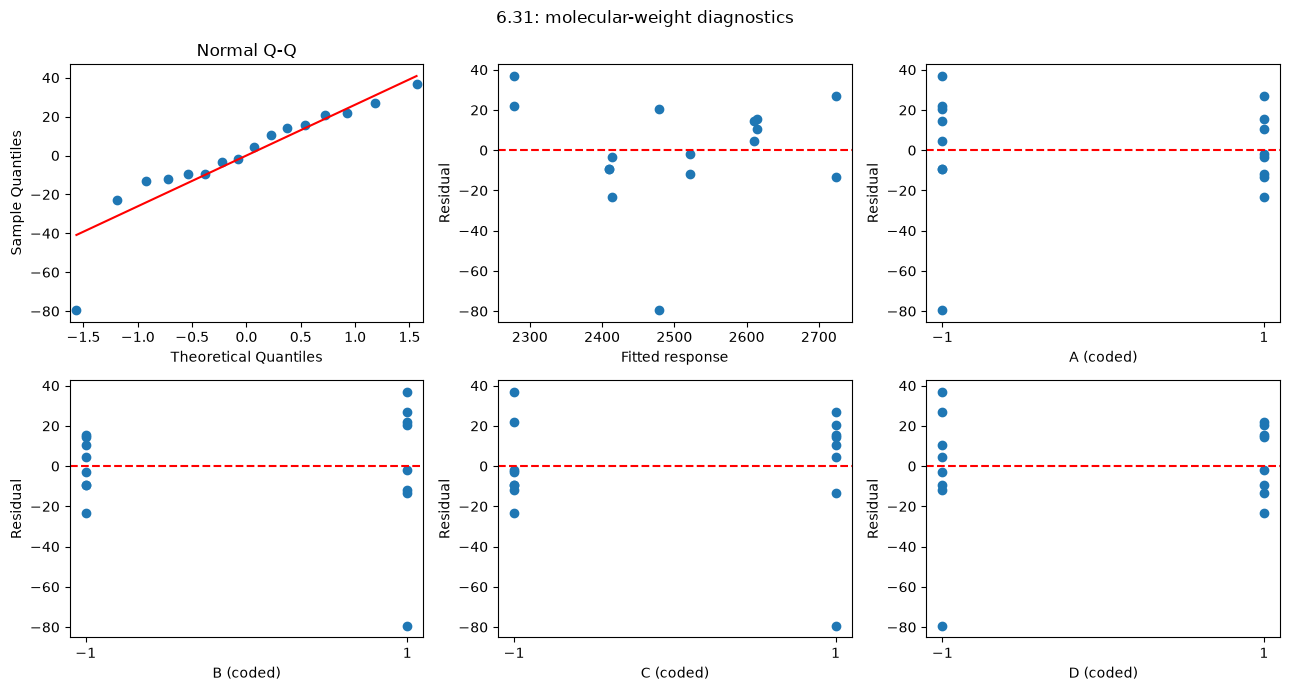

Shapiro-Wilk H0: normal errors. W = 0.868068, p = 0.0254091: reject H0


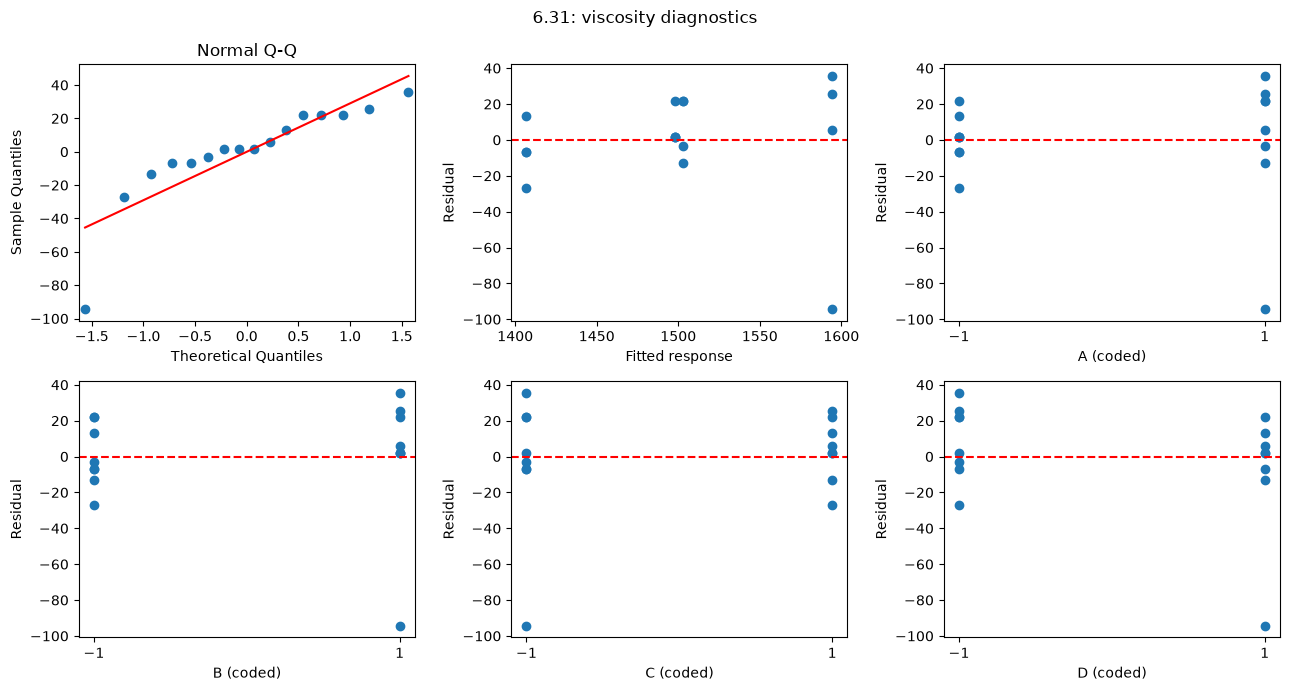

Shapiro-Wilk H0: normal errors. W = 0.793373, p = 0.00222696: reject H0


,response,run (1-based),observed,residual,studentized external,Cook D
0,Weight,7,2400.0,-79.375,-7.252999,0.840271
1,Viscosity,12,1500.0,-94.375,-7.226066,0.813131


,weight all 16,weight without run 7 (sensitivity)
Intercept,2506.250,2513.465909
A,61.875,54.659091
B,-5.625,1.590909
A:B,60.000,52.784091
C,100.625,107.840909


,viscosity all 16,viscosity without run 12 (sensitivity)
Intercept,1500.625,1507.884615
A,48.125,55.384615
B,45.625,52.884615


In [31]:
diagnostics(m631w, p631, list("ABCD"), "6.31: molecular-weight diagnostics")
diagnostics(m631v, p631, list("ABCD"), "6.31: viscosity diagnostics")
influence_rows = []
for response, model in [("Weight", m631w), ("Viscosity", m631v)]:
    influence = model.get_influence()
    j = int(np.argmax(influence.cooks_distance[0]))
    influence_rows.append({"response": response, "run (1-based)": j+1,
                           "observed": p631.iloc[j][response],
                           "residual": model.resid.iloc[j],
                           "studentized external": influence.resid_studentized_external[j],
                           "Cook D": influence.cooks_distance[0][j]})
display(pd.DataFrame(influence_rows))

# Sensitivity only: the reported final fits retain all measured observations.
weight_sensitivity = smf.ols("Weight ~ A*B + C", data=p631.drop(p631.index[6])).fit()
viscosity_sensitivity = smf.ols("Viscosity ~ A + B", data=p631.drop(p631.index[11])).fit()
display(pd.DataFrame({"weight all 16": m631w.params,
                      "weight without run 7 (sensitivity)": weight_sensitivity.params}))
display(pd.DataFrame({"viscosity all 16": m631v.params,
                      "viscosity without run 12 (sensitivity)": viscosity_sensitivity.params}))

**Residuals and adequacy.** Weight fails the normality diagnostic
($W=0.8681$, $p=0.02541$), with run 7 (observed weight 2400) having residual
$-79.375$ and Cook's distance $0.8403$. Viscosity also fails
($W=0.7934$, $p=0.002227$), dominated by run 12 (observed viscosity 1500),
residual $-94.375$ and Cook's distance $0.8131$. The Q-Q plots show these tails;
neither model should be described as having verified normal errors. Plots against
the omitted factors do not justify ignoring these unusual observations or adding
terms simply to fit them.

The sensitivity fits preserve the positive dominant weight effects $A,C,AB$ and
positive viscosity slopes $A,B$. They show why the broad directions are useful,
while the small $B$ weight coefficient and numerical predictions are less secure.
There is no recorded measurement error that would justify deleting either run;
all final predictions use all 16 observations. Check the laboratory records and
collect independent replicates before relying on precision or formal error rates.

**Conclusion.** Time and the temperature–catalyst interaction drive molecular
weight; low temperature and low catalyst concentration reduce viscosity. The models
are useful exploratory summaries, with important adequacy concerns from influential
observations and non-normal residuals.

**Problem 6.32.** Use the regression models for molecular weight and viscosity to answer the following questions.

(a) Construct a response surface contour plot for molecular weight. In what direction would you adjust the process variables
to increase molecular weight?

(b) Construct a response surface contour plot for viscosity. In what direction would you adjust the process variables to
decrease viscosity?

(c) What operating conditions would you recommend if it was necessary to produce a product with molecular weight between
2400 and 2500 and the lowest possible viscosity?

**Solution 6.32 (a), (b).** Plot the weight surface in temperature and catalyst
concentration at both time limits, and the viscosity surface in the same variables.
Pressure is absent from both selected models.

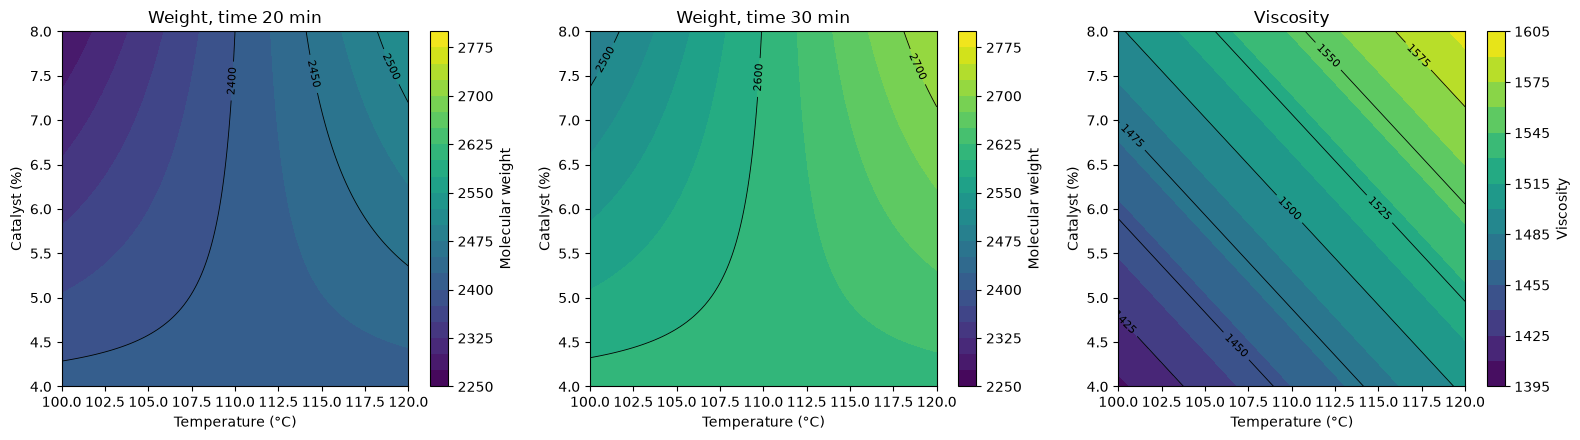

In [32]:
g = np.linspace(-1, 1, 101)
aa, bb = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, c, t in zip(axes[:2], [-1, 1], [20, 30]):
    grid = pd.DataFrame({"A": aa.ravel(), "B": bb.ravel(), "C": c})
    zz = m631w.predict(grid).to_numpy().reshape(aa.shape)
    cs = ax.contourf(110+10*aa, 6+2*bb, zz, levels=np.arange(2250, 2801, 25))
    ax.clabel(ax.contour(110+10*aa, 6+2*bb, zz, levels=[2400, 2450, 2500, 2600, 2700],
                        colors="k", linewidths=0.6), fontsize=8)
    fig.colorbar(cs, ax=ax, label="Molecular weight")
    ax.set(xlabel="Temperature (°C)", ylabel="Catalyst (%)", title=f"Weight, time {t} min")
grid = pd.DataFrame({"A": aa.ravel(), "B": bb.ravel()})
zz = m631v.predict(grid).to_numpy().reshape(aa.shape)
cs = axes[2].contourf(110+10*aa, 6+2*bb, zz, levels=15)
axes[2].clabel(axes[2].contour(110+10*aa, 6+2*bb, zz, colors="k", linewidths=0.6), fontsize=8)
axes[2].set(xlabel="Temperature (°C)", ylabel="Catalyst (%)", title="Viscosity")
fig.colorbar(cs, ax=axes[2], label="Viscosity")
plt.tight_layout()
plt.show()

To increase weight, increase time ($\partial\hat W/\partial C=100.625$).
Increasing temperature also increases weight throughout the cube, but its slope
$61.875+60B$ ranges from $1.875$ at low catalyst to $121.875$ at high catalyst.
Increasing catalyst raises weight only when $A>5.625/60=0.09375$
(temperature above 110.9375 °C); below this it lowers weight.
To decrease viscosity, lower both temperature and catalyst concentration; time
does not change predicted viscosity in the selected model.

**(c)** The viscosity equation has positive $A$ and $B$ slopes, so its global
minimum in the cube occurs at $A=B=-1$ (100 °C, 4%). At these settings
$\hat W=2510+100.625C$ and $\hat V=1406.875$. The weight constraint therefore
permits $-1\le C\le-10/100.625\simeq-0.09938$, or time from 20 to
24.5031 min. All these settings share the same minimum predicted viscosity.
Targeting weight 2450 instead of the edge of the allowed interval gives the
following interior time setting.

In [33]:
c_target = (2450 - 2510) / 100.625
recommended631 = pd.DataFrame({"A": [-1.0], "B": [-1.0], "C": [c_target]})
print(f"Recommended: temperature 100 °C, catalyst 4%, time {25+5*c_target:.6f} min;")
print("pressure may be chosen within 60–75 psi for practical/cost reasons.")
print("Predicted weight:", m631w.predict(recommended631).iloc[0])
print("Predicted viscosity:", m631v.predict(recommended631).iloc[0])
print("Weight prediction uncertainty (conditional normal-error model):")
display(m631w.get_prediction(recommended631).summary_frame(alpha=alpha))
print("Viscosity prediction uncertainty (same caveat):")
display(m631v.get_prediction(recommended631).summary_frame(alpha=alpha))

Recommended: temperature 100 °C, catalyst 4%, time 22.018634 min;
pressure may be chosen within 60–75 psi for practical/cost reasons.
Predicted weight: 2450.0000000000014
Predicted viscosity: 1406.875000000001
Weight prediction uncertainty (conditional normal-error model):


,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,2450.0,16.428673,2413.840735,2486.159265,2371.830049,2528.169951


Viscosity prediction uncertainty (same caveat):


,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,1406.875,13.944214,1376.750357,1436.999643,1331.062978,1482.687022


**Conclusion.** Recommend 100 °C, 4% catalyst and approximately 22.0186 min,
with pressure chosen within the tested range. This gives predicted weight 2450
and viscosity 1406.875. The weight constraint applies to the fitted mean, not a
guarantee that every product meets specification: the displayed prediction interval
and the diagnostics from 6.31 call for confirmation runs before production use.

### Problem 6.36: resistivity of a silicon wafer

Resistivity on a silicon wafer is influenced by several factors. The results of a single replicate of a $2^4$ factorial
experiment performed during a critical processing step are (standard order):

In [34]:
p636 = pd.DataFrame([r[::-1] for r in itertools.product([-1, 1], repeat=4)], columns=list("ABCD"))
p636["resistivity"] = [1.92, 11.28, 1.09, 5.75, 2.13, 9.53, 1.03, 5.35,
                       1.60, 11.73, 1.16, 4.68, 2.16, 9.11, 1.07, 5.30]
p636

,A,B,C,D,resistivity
0,-1,-1,-1,-1,1.92
1,1,-1,-1,-1,11.28
2,-1,1,-1,-1,1.09
3,1,1,-1,-1,5.75
4,-1,-1,1,-1,2.13
5,1,-1,1,-1,9.53
6,-1,1,1,-1,1.03
7,1,1,1,-1,5.35
8,-1,-1,-1,1,1.60
9,1,-1,-1,1,11.73


**Problem 6.36**

(a) Estimate the factor effects. Plot the effect estimates on a normal probability plot and select a tentative model.

(b) Fit the model identified in part (a) and analyze the residuals. Is there any indication of model inadequacy?

(c) Repeat the analysis from parts (a) and (b) using $\ln(y)$ as the response variable. Is there an indication that the
transformation has been useful?

(d) Fit a model in terms of the coded variables that can be used to predict the resistivity.

**Solution 6.36 (a), (b).** On the original scale, $A$, $B$ and $AB$ exceed
$SME=1.4971$ and are separated from the small effects. Fit the hierarchical
model $A*B$ and pool the other twelve contrasts as error.

,contrast,effect,SS,coef
term,,,,
A,50.57,6.32125,159.832806,3.160625
B,-24.03,-3.00375,36.090056,-1.501875
A:B,-17.11,-2.13875,18.297006,-1.069375
C,-3.53,-0.44125,0.778806,-0.220625
A:C,-4.77,-0.59625,1.422056,-0.298125
B:C,3.67,0.45875,0.841806,0.229375
A:B:C,5.51,0.68875,1.897506,0.344375
D,-1.27,-0.15875,0.100806,-0.079375
A:D,-0.91,-0.11375,0.051756,-0.056875


,Lenth thresholds
s0,0.425625
PSE,0.286875
ME,0.737436
SME,1.497101


Exceed ME: ['A', 'B', 'AB']
Exceed SME: ['A', 'B', 'AB']


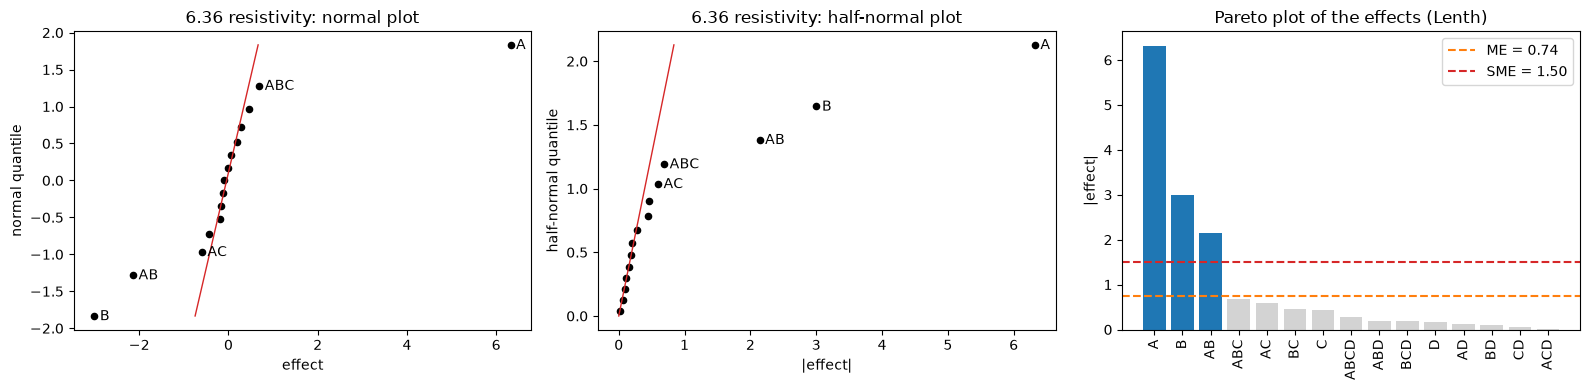

6.36: original scale 
Formula: resistivity ~ A*B


,coded coefficient
Intercept,4.680625
A,3.160625
B,-1.501875
A:B,-1.069375


,df,sum_sq,mean_sq,F,PR(>F),df denominator,decision (0.05)
A,1.0,159.832806,159.832806,333.087657,4.049458e-10,12.0,reject H0
B,1.0,36.090056,36.090056,75.210794,1.630379e-06,12.0,reject H0
A:B,1.0,18.297006,18.297006,38.130513,4.762882e-05,12.0,reject H0
Residual,12.0,5.758225,0.479852,NaN,NaN,12.0,error estimate


Overall H0: all slopes = 0; F(3, 12) = 148.81, p = 9.32787e-10; reject H0
SSE = 5.75823; MSE = 0.479852; s = 0.692714; R2 = 0.973824


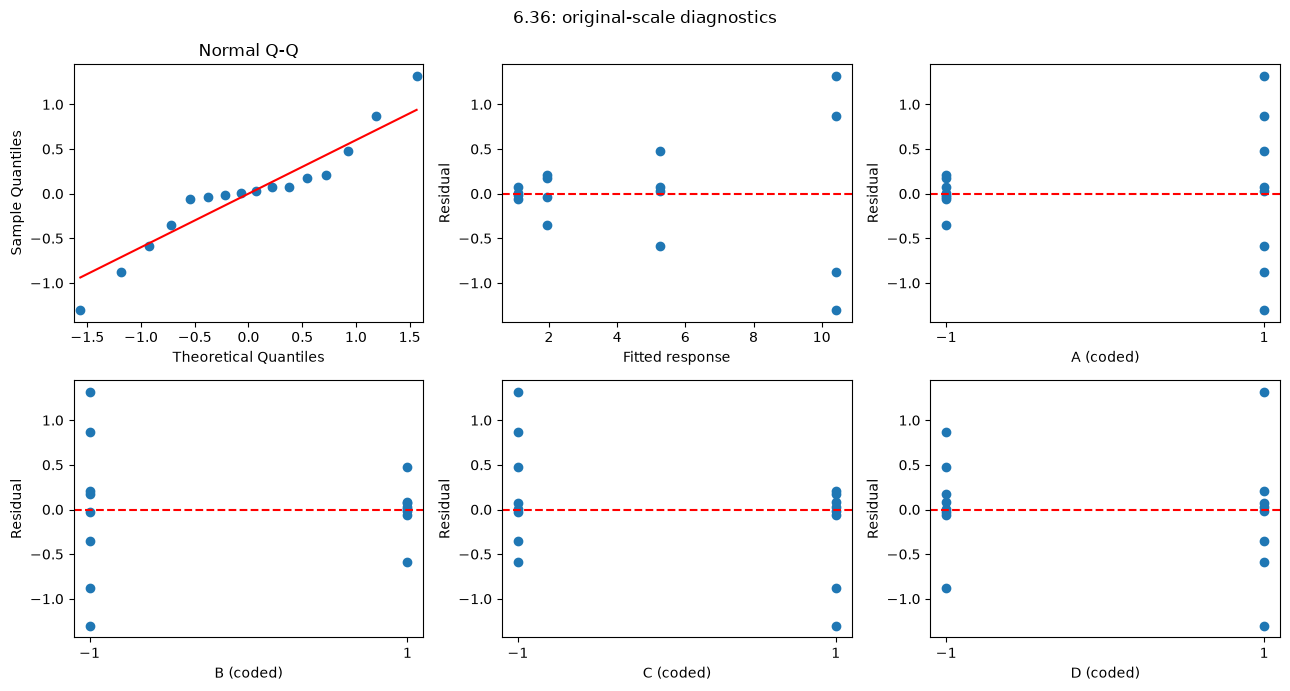

Shapiro-Wilk H0: normal errors. W = 0.942847, p = 0.385357: do not reject H0


,count,var,std
A,,,
-1,8,0.029821,0.172689
1,8,0.792782,0.890383


In [35]:
e636raw, limits636raw = screen(p636, "resistivity", list("ABCD"), title="6.36 resistivity")
m636raw = smf.ols("resistivity ~ A*B", data=p636).fit()
a636raw = report_model(m636raw, "6.36: original scale")
diagnostics(m636raw, p636, list("ABCD"), "6.36: original-scale diagnostics")
display(p636.assign(residual=m636raw.resid).groupby("A").residual.agg(["count", "var", "std"]))

The raw fitted equation is
$$\hat y=4.680625+3.160625A-1.501875B-1.069375AB.$$
The individual term tests all reject ($F_A=333.0877$, $F_B=75.2108$,
$F_{AB}=38.1305$, with $p<0.00005$ for each); $MS_E=0.4798521$ on 12 df.
However, the residual spread is much larger at high $A$: variances $0.7928$
versus $0.02982$, a ratio about 26.6. This is a strong funnel despite
Shapiro–Wilk not rejecting normality ($W=0.9428$, $p=0.3854$).
The constant-variance assumption is questionable, so the raw ANOVA alone is not
a satisfactory final analysis.

**(c)** Resistivity is positive and its variability grows with its level, making
$\log(y)$ a reasonable variance-stabilizing transformation. Recompute all effects
on that scale rather than transforming the already estimated effects.

,contrast,effect,SS,coef
term,,,,
A,13.005926,1.625741,10.572131,0.812870
B,-5.028441,-0.628555,1.580326,-0.314278
A:B,-0.394953,-0.049369,0.009749,-0.024685
C,-0.102537,-0.012817,0.000657,-0.006409
A:C,-0.635579,-0.079447,0.025248,-0.039724
B:C,-0.067613,-0.008452,0.000286,-0.004226
A:B:C,1.014951,0.126869,0.064383,0.063434
D,-0.289238,-0.036155,0.005229,-0.018077
A:D,-0.153252,-0.019156,0.001468,-0.009578


,Lenth thresholds
s0,0.054232
PSE,0.053341
ME,0.137118
SME,0.278370


Exceed ME: ['A', 'B']
Exceed SME: ['A', 'B']


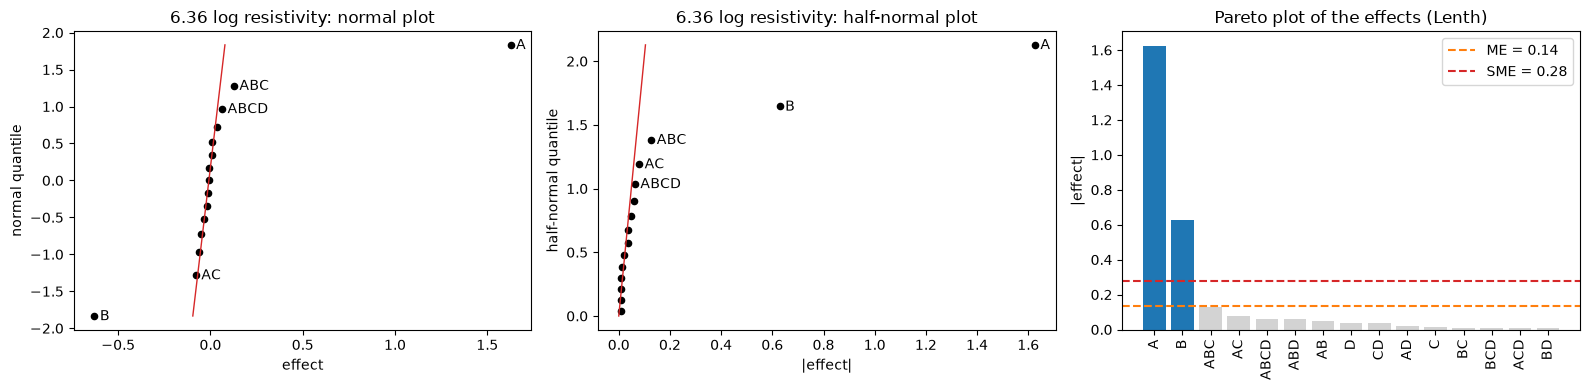

6.36: log-scale final model 
Formula: log_y ~ A + B


,coded coefficient
Intercept,1.185417
A,0.812870
B,-0.314278


,df,sum_sq,mean_sq,F,PR(>F),df denominator,decision (0.05)
A,1.0,10.572131,10.572131,962.945399,1.407708e-13,13.0,reject H0
B,1.0,1.580326,1.580326,143.941436,2.094865e-08,13.0,reject H0
Residual,13.0,0.142726,0.010979,NaN,NaN,13.0,error estimate


Overall H0: all slopes = 0; F(2, 13) = 553.443, p = 2.63633e-13; reject H0
SSE = 0.142726; MSE = 0.010979; s = 0.10478; R2 = 0.988392


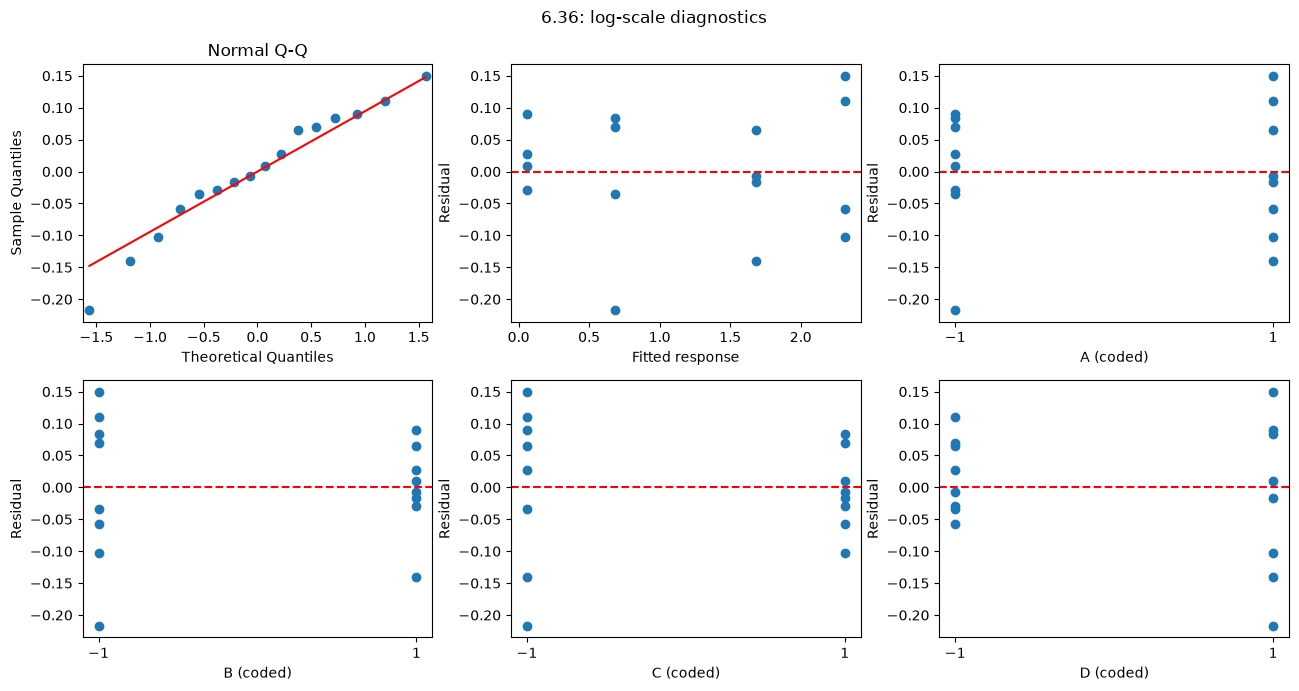

Shapiro-Wilk H0: normal errors. W = 0.966795, p = 0.784398: do not reject H0


,count,var,std
A,,,
-1,8,0.009965,0.099827
1,8,0.010424,0.102098


Nested test H0: beta_AB = 0 on the log scale; H1: beta_AB != 0


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,13.0,0.142726,0.0,NaN,NaN,NaN
1,12.0,0.132977,1.0,0.009749,0.879783,0.366757


F(1,12) = 0.879783, p = 0.366757: do not reject H0.


In [36]:
p636["log_y"] = np.log(p636.resistivity)
e636log, limits636log = screen(p636, "log_y", list("ABCD"), title="6.36 log resistivity")
m636log = smf.ols("log_y ~ A + B", data=p636).fit()
a636log = report_model(m636log, "6.36: log-scale final model")
diagnostics(m636log, p636, list("ABCD"), "6.36: log-scale diagnostics")
display(p636.assign(residual=m636log.resid).groupby("A").residual.agg(["count", "var", "std"]))

# Check whether the raw-scale interaction remains necessary after transformation.
m636log_ab = smf.ols("log_y ~ A*B", data=p636).fit()
print("Nested test H0: beta_AB = 0 on the log scale; H1: beta_AB != 0")
display(anova_lm(m636log, m636log_ab))
f_ab = (m636log.ssr - m636log_ab.ssr) / m636log_ab.mse_resid
p_ab = stats.f.sf(f_ab, 1, m636log_ab.df_resid)
print(f"F(1,12) = {f_ab:.6g}, p = {p_ab:.6g}: do not reject H0.")

Now $A=1.625741$ and $B=-0.628555$ exceed $SME=0.278370$;
$AB=-0.049369$ is below $ME=0.137118$. Drop $AB$ and retain $A+B$.
The nested interaction test gives $F(1,12)=0.8798$, $p=0.3668$,
so it does not contradict this simpler model. The final main-effect tests reject
their zero-slope nulls ($F_A=962.9454$, $p=1.408\times10^{-13}$;
$F_B=143.9414$, $p=2.095\times10^{-8}$).

The final log-model error mean square is $0.0109789$ on 13 df.
Residual variances at low and high $A$ are now $0.009965$ and $0.010424$;
the funnel largely disappears. Shapiro–Wilk gives $W=0.9668$, $p=0.7844$,
so it does not reject normality. No clear residual pattern against the omitted
$C,D$ requires another term, although 16 observations cannot prove adequacy.

**(d)** The final coded model is
$$\widehat{\log y}=1.185417+0.812870A-0.314278B.$$
On the original scale, exponentiating predicts the conditional **median**:
$$\widehat{\mathrm{median}}(y\mid A,B)
=\exp(1.185417+0.812870A-0.314278B).$$
Under an additional normal constant-variance log-error assumption, the conditional
mean is approximately this value times $\exp(MS_E/2)$; treating the variance
estimate as exact makes this a plug-in correction, not an exact unbiased estimator.

In [37]:
pred636 = pd.DataFrame(list(itertools.product([-1, 1], repeat=2)), columns=["A", "B"])
pred636["log prediction"] = m636log.predict(pred636)
pred636["predicted median"] = np.exp(pred636["log prediction"])
pred636["mean (lognormal plug-in)"] = np.exp(pred636["log prediction"] + m636log.mse_resid/2)
display(pred636)
print("High/low A multiplicative median ratio:", np.exp(2*m636log.params["A"]))
print("High/low B multiplicative median ratio:", np.exp(2*m636log.params["B"]))

,A,B,log prediction,predicted median,mean (lognormal plug-in)
0,-1,-1,0.686824,1.987394,1.998334
1,-1,1,0.058269,1.060000,1.065835
2,1,-1,2.312565,10.100299,10.155897
3,1,1,1.684010,5.387115,5.416768


High/low A multiplicative median ratio: 5.082181961673636
High/low B multiplicative median ratio: 0.5333618953836015


**Conclusion.** Use the log-scale $A+B$ model for prediction: it is simpler and
substantially stabilizes the variance. Increasing $A$ multiplies the predicted
median by about 5.08 and increasing $B$ multiplies it by about 0.533; the apparent
raw interaction is consistent with this multiplicative response.

### Reproducibility checks

The following checks verify factorial coding, use of only the intended runs,
contrast/regression agreement, the pooled-error decomposition and the recommended
mean-weight constraint. They are numerical identities, not additional hypothesis tests.

In [38]:
for data in [p628, p631, p636]:
    assert len(data) == 16
    assert set(np.unique(data[list("ABCD")].to_numpy())) == {-1, 1}
    assert len(data.drop_duplicates(list("ABCD"))) == 16
for data, response, model in [(p628, "Yield", m628), (p631, "Weight", m631w),
                               (p631, "Viscosity", m631v),
                               (p636, "resistivity", m636raw), (p636, "log_y", m636log)]:
    table = effects_2k(data, response, list("ABCD"))
    slopes = model.params.drop("Intercept")
    assert np.allclose(2*slopes, table.loc[slopes.index, "effect"])
    assert np.isclose(model.ssr, table.drop(slopes.index).SS.sum())
assert np.isclose(m631w.predict(recommended631).iloc[0], 2450)
assert np.isclose(m631v.predict(recommended631).iloc[0], 1406.875)
print("All numerical checks passed.")

All numerical checks passed.
